# Fase 1 · Datos y EDA — Chatbot incluyente de PQRS en salud (WhatsApp)

**Proyecto:** chatbot de NLP que recibe **Peticiones, Quejas, Reclamos y Sugerencias (PQRS)** de atención en salud por WhatsApp Business, con soporte básico en **wayuunaiki** y **lenguaje simplificado** para personas con baja alfabetización.

El chatbot necesita dos tipos de datos, y este notebook analiza ambos:

| Componente del bot | Dato que lo alimenta | Sección |
|---|---|---|
| Clasificador de intenciones (BERT en español / spaCy + reglas) | **Dataset PQRS** de mensajes etiquetados (tipo PQRS + intención) | 8 |
| Soporte en wayuunaiki (detección de idioma, glosario, respuestas bilingües) | **Corpus paralelo español ↔ wayuunaiki** (`wayuu.zip`) | 1 – 7 |

**Contenido**

0. Fuentes de datos identificadas
1. Configuración y carga del corpus paralelo
2. Descripción del corpus
3. Estadísticas descriptivas
4. Visualizaciones
5. Problemas de calidad del corpus (nulos, duplicados, desbalance de fuentes, normalización, outliers, fuga entre splits, contaminación)
6. Resumen de hallazgos del corpus
7. **El corpus frente al dominio del chatbot (salud)**: cobertura de vocabulario, glosario de salud y validación cruzada con UNICISO
8. **Dataset PQRS sintético**: generación, descripción, estadísticas, visualizaciones y calidad (nulos, duplicados, outliers, **desbalance de clases**, ambigüedad, fuga)
9. **Conclusiones de la Fase 1 y decisiones para la Fase 2**

Anexo · Prototipo de detector de idioma y traductor por memoria (adelanto de la Fase 2)

## 0. Fuentes de datos identificadas

| # | Fuente | Tipo | Uso en el chatbot | Tamaño | Estado / observaciones |
|---|---|---|---|---|---|
| F1 | **Corpus paralelo español ↔ wayuunaiki** (`wayuu.zip`, 16 CSV en 4 familias con train/dev/test) | **Dataset público** — corpus consolidado a partir de recursos digitales existentes (Universidad de los Andes, AmericasNLP 2024). *Confirmar la URL exacta de descarga y la licencia en el informe.* | Detección de idioma, glosario esp↔way, plantillas de respuesta bilingües, futuro modelo de traducción | 82.218 pares (`completo_v2`) | Disponible. Dominio mayoritariamente religioso/formal → poca cobertura de salud (sección 7) |
| F2 | **Dataset PQRS en salud** (`pqrs_salud_sintetico.csv`) | **Generación sintética** propia: plantillas + variación de registro (formal / coloquial / simplificado) + code-switching con wayuunaiki + ruido de WhatsApp | Entrenar y evaluar el **clasificador de intenciones** (variable objetivo `tipo_pqrs` y `intencion`) | ≈ 3.200 mensajes | Generado en la sección 8 con semilla fija (reproducible). Debe validarse con personal de atención al usuario |
| F3 | **Glosario de salud esp → way** extraído de F1 y completado con F6 | **Datos propios** derivados | Respuestas en lenguaje sencillo con términos clave en wayuunaiki | decenas de términos | Sección 7.2. Requiere validación por hablantes nativos |
| F6 | **Audios "Enfermedades en wayuunaiki"** — Portal UNICISO (colaboración wayuu: Kelly Johana López Epieyu y Sharol Robles Epieyu) | **Recurso público** educativo (audio + texto) | Completar y validar el glosario de salud; audios útiles a futuro para respuestas por nota de voz | 10 términos | Sección 7.3. Citar al portal y a las colaboradoras; revisar condiciones de uso antes de redistribuir los audios |
| F4 | Normativa de PQRS (definiciones de petición, queja, reclamo, sugerencia; tiempos de respuesta) | Documentación pública (Superintendencia Nacional de Salud / Ley 1755 de 2015) | Definir las etiquetas y las respuestas del bot | — | Base para la guía de etiquetado |
| F5 | Conversaciones reales anonimizadas de WhatsApp de una EPS/IPS | **Datos propios** (futuros) | Validación del modelo con datos reales | — | No disponible aún; requiere convenio, consentimiento y anonimización (Ley 1581 de 2012) |

> **Por qué datos sintéticos:** no existe un dataset público de PQRS de salud en Colombia, menos aún con mensajes en wayuunaiki o de personas con baja alfabetización. La generación sintética permite arrancar, pero su distribución refleja las decisiones de quien la diseña; por eso su EDA (sección 8) se enfoca en detectar los sesgos que eso introduce.

## 1. Configuración y carga de datos

In [1]:
import re, zipfile, unicodedata, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.labelsize": 10})
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

In [2]:
# ── Localizar el zip (funciona en Jupyter local y en Google Colab) ──────────────
CANDIDATES = [
    "../data/external/wayuu.zip",               # estructura del repositorio
    "wayuu.zip",
    "/content/wayuu.zip",                       # Colab: archivo subido
    "/content/drive/MyDrive/wayuu.zip",         # Colab: Google Drive montado
    "/mnt/user-data/uploads/wayuu.zip",
]
zip_path = next((Path(p) for p in CANDIDATES if Path(p).exists()), None)

if zip_path is None:
    try:                                        # Colab: pedir el archivo
        from google.colab import files
        up = files.upload()
        zip_path = Path(next(iter(up)))
    except ImportError:
        raise FileNotFoundError("Coloca wayuu.zip junto al notebook o edita CANDIDATES.")

EXTRACT_DIR = Path("../data/external/wayuu_data") if Path("../data/external").exists() else Path("wayuu_data")
if not EXTRACT_DIR.exists():
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(EXTRACT_DIR)

csv_files = sorted(EXTRACT_DIR.rglob("*.csv"))
DATA_DIR = csv_files[0].parent

# Archivos sueltos que no venían dentro del zip (p. ej. el dev de completo_v2 entregado aparte)
EXTRA = ["wayuu_completo_v2_dev.csv"]
SEARCH_DIRS = [Path("."), Path("/content"), Path("/content/drive/MyDrive"), Path("/mnt/user-data/uploads")]
import shutil
for name in EXTRA:
    if not (DATA_DIR / name).exists():
        src = next((d / name for d in SEARCH_DIRS if (d / name).exists()), None)
        if src is not None:
            shutil.copy(src, DATA_DIR / name); print(f"Incorporado archivo externo: {name}")
        else:
            print(f"⚠ {name} no encontrado: se analizará sin él.")
csv_files = sorted(DATA_DIR.glob("*.csv"))
print(f"Zip: {zip_path}  →  {len(csv_files)} CSV en {DATA_DIR}")

Zip: ../data/external/wayuu.zip  →  16 CSV en ../data/external/wayuu_data/wayuu


In [3]:
# ── Cargar TODOS los CSV con el mismo criterio ─────────────────────────────────
# keep_default_na=False: evita que pandas convierta textos como "NA" o "nan" en nulos
# (importante en un idioma donde "na" es una palabra común).
def parse_name(stem):
    split = "full"
    for s in ("train", "dev", "test"):
        if stem.endswith("_" + s):
            split, stem = s, stem[: -len(s) - 1]
            break
    family = {"wayuu_completo_sin_dic_v2": "sin_dic_v2", "wayuu_completo_v2": "completo_v2",
              "wayuu_completo": "completo", "wayuu_sin_dict": "sin_dict"}[stem]
    return family, split

raw, data, meta = {}, {}, []
for p in csv_files:
    df0 = pd.read_csv(p, dtype=str, keep_default_na=False)
    fam, split = parse_name(p.stem)
    col_order = "→".join(df0.columns)
    assert set(df0.columns) == {"esp", "way"}, p.name
    data[p.name] = df0[["esp", "way"]].reset_index(drop=True)      # orden de columnas unificado
    # lectura "por defecto" para detectar valores que pandas habría tomado como nulos
    d_def = pd.read_csv(p)
    meta.append(dict(archivo=p.name, familia=fam, split=split, filas=len(df0),
                     orden_columnas=col_order, tam_KB=round(p.stat().st_size / 1024, 1),
                     pares_duplicados=int(df0.duplicated().sum()),
                     NaN_pandas_por_defecto=int(d_def.isna().sum().sum())))

inv = (pd.DataFrame(meta)
         .assign(pct_dup=lambda d: (100 * d.pares_duplicados / d.filas).round(2))
         .sort_values(["familia", "split"], key=lambda s: s.map({"full": 0, "train": 1, "dev": 2, "test": 3}).fillna(s)
                      if s.name == "split" else s)
         .reset_index(drop=True))
display(inv)

,archivo,familia,split,filas,orden_columnas,tam_KB,pares_duplicados,NaN_pandas_por_defecto,pct_dup
0,wayuu_completo.csv,completo,full,75959,esp→way,9812.2,2175,0,2.86
1,wayuu_completo_train.csv,completo,train,60767,esp→way,7833.6,1538,0,2.53
2,wayuu_completo_dev.csv,completo,dev,7596,esp→way,999.1,50,0,0.66
3,wayuu_completo_test.csv,completo,test,7596,esp→way,979.6,71,0,0.93
4,wayuu_completo_v2.csv,completo_v2,full,82218,esp→way,12154.2,2188,0,2.66
5,wayuu_completo_v2_train.csv,completo_v2,train,65774,esp→way,9700.4,1563,0,2.38
6,wayuu_completo_v2_dev.csv,completo_v2,dev,8222,esp→way,1239.6,54,0,0.66
7,wayuu_completo_v2_test.csv,completo_v2,test,8222,esp→way,1214.2,75,0,0.91
8,wayuu_completo_sin_dic_v2.csv,sin_dic_v2,full,7635,way→esp,2496.9,73,0,0.96
9,wayuu_completo_sin_dic_v2_train.csv,sin_dic_v2,train,6108,way→esp,1991.1,44,0,0.72


## 2. Descripción del dataset

### 2.1 Estructura general
Cada archivo tiene **dos columnas de texto**: `esp` (español) y `way` (wayuunaiki). Cada fila es un par de traducción. Los archivos se agrupan en **4 familias**, cada una con su archivo completo y particiones `train/dev/test`.

In [4]:
fam_summary = (inv.pivot_table(index="familia", columns="split", values="filas", aggfunc="sum")
                  .reindex(columns=["full", "train", "dev", "test"]))
fam_summary["suma_particiones"] = fam_summary[["train", "dev", "test"]].sum(axis=1)
fam_summary["diferencia_vs_full"] = fam_summary["full"] - fam_summary["suma_particiones"]
for s in ("train", "dev", "test"):
    fam_summary[f"%{s}"] = (100 * fam_summary[s] / fam_summary["suma_particiones"]).round(1)
display(fam_summary.fillna("—"))
print("Orden de columnas por familia:")
display(inv.groupby("familia").orden_columnas.unique().to_frame())

split,full,train,dev,test,suma_particiones,diferencia_vs_full,%train,%dev,%test
familia,,,,,,,,,
completo,75959,60767,7596,7596,75959,0,80.0,10.0,10.0
completo_v2,82218,65774,8222,8222,82218,0,80.0,10.0,10.0
sin_dic_v2,7635,6108,763,764,7635,0,80.0,10.0,10.0
sin_dict,1376,1100,138,138,1376,0,79.9,10.0,10.0


Orden de columnas por familia:


,orden_columnas
familia,
completo,[esp→way]
completo_v2,[esp→way]
sin_dic_v2,[way→esp]
sin_dict,[way→esp]


### 2.2 Relación entre las familias de archivos
Comprobamos con código cómo se relacionan los archivos (subconjuntos, prefijos, particiones que suman el total…).

In [5]:
key = lambda d: set(zip(d.esp, d.way))
c1, c2 = data["wayuu_completo.csv"], data["wayuu_completo_v2.csv"]
sd, sd2 = data["wayuu_sin_dict.csv"], data["wayuu_completo_sin_dic_v2.csv"]

rel = {
 "completo es prefijo exacto de completo_v2 (mismo orden)":      c2.iloc[:len(c1)].reset_index(drop=True).equals(c1),
 "filas añadidas por completo_v2 al final":                      len(c2) - len(c1),
 "pares únicos de completo_v2 ausentes en completo":             len(key(c2) - key(c1)),
 "sin_dict ⊂ completo (pares únicos incluidos / total)":         f"{len(key(sd) & key(c1))} / {len(key(sd))}",
 "sin_dic_v2 ⊂ completo_v2 (pares únicos incluidos / total)":    f"{len(key(sd2) & key(c2))} / {len(key(sd2))}",
 "sin_dic_v2 − sin_dict (pares nuevos)":                         len(key(sd2) - key(sd)),
}
display(pd.Series(rel, name="valor").to_frame())

# ¿Las particiones reconstruyen el archivo completo? (como conjunto de pares)
for fam, full in [("completo", "wayuu_completo.csv"), ("completo_v2", "wayuu_completo_v2.csv"),
                  ("sin_dict", "wayuu_sin_dict.csv"), ("sin_dic_v2", "wayuu_completo_sin_dic_v2.csv")]:
    parts = inv[(inv.familia == fam) & (inv.split != "full")]
    union = set().union(*[key(data[f]) for f in parts.archivo])
    missing = len(key(data[full]) - union)
    print(f"{fam:12s} splits presentes: {sorted(parts.split)}  | pares del 'full' que no están en ningún split: {missing}")

,valor
completo es prefijo exacto de completo_v2 (mismo orden),True
filas añadidas por completo_v2 al final,6259
pares únicos de completo_v2 ausentes en completo,6246
sin_dict ⊂ completo (pares únicos incluidos / total),1316 / 1316
sin_dic_v2 ⊂ completo_v2 (pares únicos incluidos / total),7562 / 7562
sin_dic_v2 − sin_dict (pares nuevos),6246


completo     splits presentes: ['dev', 'test', 'train']  | pares del 'full' que no están en ningún split: 0
completo_v2  splits presentes: ['dev', 'test', 'train']  | pares del 'full' que no están en ningún split: 0
sin_dict     splits presentes: ['dev', 'test', 'train']  | pares del 'full' que no están en ningún split: 0
sin_dic_v2   splits presentes: ['dev', 'test', 'train']  | pares del 'full' que no están en ningún split: 0


**Lectura:**
- `completo_v2` = `completo` + filas nuevas al final (el orden original se conserva → los datos **no están barajados**, lo que luego permite detectar “bloques” de distinta procedencia).
- Los archivos `*sin_dic*`/`sin_dict` son el subconjunto de **oraciones** (sin entradas de diccionario) y tienen **columnas invertidas** (`way,esp`) respecto a los `completo` (`esp,way`). Esto se unificó arriba.
- El zip original **no incluía `wayuu_completo_v2_dev.csv`** (`train + test` sumaban 73.996 de 82.218 filas; la diferencia, 8.222, coincide con el tamaño de `test`). Ese archivo se entregó por separado y aquí se incorpora: con él las tres particiones reconstruyen exactamente el total (80/10/10) y no queda ningún par sin asignar.

Trabajaremos como **dataset principal** con `wayuu_completo_v2.csv` (el más completo) y usaremos las demás familias para comparar particiones y fuga de datos.

In [6]:
MAIN = "wayuu_completo_v2.csv"
df = data[MAIN].copy()
print(f"Dataset principal: {MAIN} → {df.shape[0]:,} pares")
display(df.sample(10, random_state=7))

Dataset principal: wayuu_completo_v2.csv → 82,218 pares


,esp,way
41595,a fin de ayudar a la persona a razonar sobre ese texto podriamos usar el siguiente arg...,aapünüsü laülawaa nümüin sünain kojutüinjachin nia sütüma wayuu noulia napüshua na sül...
6614,no estoy asustado,nnojoishi taya mmoluin
24724,cuatro,pienchi
60007,porque el nombre de dios aparece en esos versiculos en los rollos del mar muerto que h...,shia süka eein tia nünüliakat maleiwa sulu'u tü rooyo chajatkat chaa mar muerto tia ro...
42543,por ejemplo como reaccionamos cuando un adolescente no elige bien sus diversiones o de...,jamüshija'a eere wanee jima'ai eekai nüshaittüin nünajüin jee naapajüin wanee kasa nno...
31211,pues bien lea la biblia y medite diariamente en los pensamientos de dios,paashaje'era tü wiwüliakat otta jülüja paa'in waneepia tü nümakat pümüin maleiwa yala ...
50101,en ella leemos entonces habra gran tribulacion como la cual no ha sucedido una desde e...,müsü sünüiki so'uweena ka'ikat tia alana'aleejeeria ma'i tü müliaa shi'reetkat wayuu s...
75805,"Yo no tengo chivos, y tampoco tengo ovejos.","Makaa'ulainsai taya, manneetsesai taya ya'asa ."
23838,ese alijuna se acordaba de su padre,sotomuyuu aa in nüshi chira alijunakai
59058,por eso es tan importante que siempre meditemos en la biblia y que cada dia conozcamos...,naashin jesuu naapaale wanee wayuu tü nünüikikat maleiwa mojusheeka eemiajaajeerü nuno...


## 3. Estadísticas descriptivas

In [7]:
# Tokenizador: palabras con apóstrofos internos (el saltillo ' forma parte de la palabra en wayuunaiki)
APOS = "'’‘ʼꞌꞋ`´"
TOKEN_RE = re.compile(rf"[^\W\d_]+(?:[{APOS}][^\W\d_]+)*")
tok = lambda s: TOKEN_RE.findall(s.lower())

def add_features(d):
    d = d.copy()
    for col in ("esp", "way"):
        d[f"n_pal_{col}"] = d[col].map(lambda s: len(tok(s)))
        d[f"n_car_{col}"] = d[col].str.len()
    d["ratio_pal"] = (d.n_pal_esp.clip(lower=1) / d.n_pal_way.clip(lower=1))
    d["log_ratio"] = np.log(d.ratio_pal)
    return d

df = add_features(df)
num_cols = ["n_pal_esp", "n_pal_way", "n_car_esp", "n_car_way", "ratio_pal"]
display(df[num_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(2).T)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
n_pal_esp,82218.0,11.91,13.18,1.00,1.00,2.00,4.0,10.00,17.0,29.00,40.00,1049.0
n_pal_way,82218.0,9.96,12.41,1.00,1.00,2.00,3.0,8.00,14.0,26.00,38.00,1042.0
n_car_esp,82218.0,65.80,73.88,1.00,5.00,10.00,19.0,55.00,96.0,161.00,221.00,5939.0
n_car_way,82218.0,77.67,100.05,1.00,5.00,12.00,25.0,61.00,107.0,202.00,303.00,8555.0
ratio_pal,82218.0,1.32,0.80,0.06,0.45,0.64,1.0,1.17,1.5,2.33,3.75,26.0


In [8]:
# Vocabulario por idioma
vocab = {}
for col in ("esp", "way"):
    cnt = Counter(t for s in df[col] for t in tok(s))
    n_tok, n_typ = sum(cnt.values()), len(cnt)
    hapax = sum(1 for v in cnt.values() if v == 1)
    top100 = sum(v for _, v in cnt.most_common(100)) / n_tok
    vocab[col] = cnt
    print(f"{col}: tokens={n_tok:,}  tipos={n_typ:,}  TTR={n_typ/n_tok:.3f}  "
          f"hapax={hapax:,} ({100*hapax/n_typ:.1f}% de los tipos)  top-100 cubre {100*top100:.1f}% de los tokens")

top = pd.DataFrame({
    "esp": [f"{w} ({c:,})" for w, c in vocab["esp"].most_common(15)],
    "way": [f"{w} ({c:,})" for w, c in vocab["way"].most_common(15)],
}, index=range(1, 16))
display(top)

esp: tokens=979,255  tipos=33,443  TTR=0.034  hapax=13,227 (39.6% de los tipos)  top-100 cubre 53.1% de los tokens


way: tokens=818,901  tipos=56,384  TTR=0.069  hapax=30,963 (54.9% de los tipos)  top-100 cubre 48.4% de los tokens


,esp,way
1,"que (44,477)","tü (42,376)"
2,"de (43,421)","na (17,828)"
3,"a (33,317)","süpüla (14,067)"
4,"la (28,388)","sünain (13,055)"
5,"el (25,164)","wayuu (11,731)"
6,"y (24,668)","kasa (11,606)"
7,"en (20,554)","chi (10,006)"
8,"los (16,757)","wanee (9,385)"
9,"no (12,149)","je'waa (9,264)"
10,"se (11,651)","tia (8,484)"


**Alfabeto observado en `way`** (útil para validar la ortografía; el wayuunaiki usa *a, ch, e, i, j, k, l, m, n, o, p, r, s, sh, t, u, ü, w, y* y el saltillo `'`):

In [9]:
way_chars = Counter(ch for s in df.way for ch in s)
letters = pd.Series({k: v for k, v in way_chars.items() if k.isalpha()}).sort_values(ascending=False)
core_letters = set("aeiouüjklmnprstwych")   # alfabeto nativo (ch/sh se evalúan letra a letra)
nonnative = letters[[not (ch.lower() in core_letters) for ch in letters.index]]
print(f"Letras distintas en way: {len(letters)}   |   fuera del alfabeto nativo: {len(nonnative)}")
display(nonnative.to_frame("frecuencia").T)

Letras distintas en way: 66   |   fuera del alfabeto nativo: 28


,d,b,g,ú,v,f,í,z,é,q,x,á,ó,B,G,D,F,Ꞌ,ꞌ,Z,ñ,É,Ø,V,Í,Q,Á,Ú
frecuencia,7016,4762,2869,2410,1953,1599,791,710,583,566,303,243,190,131,118,117,95,90,87,51,25,24,11,9,2,2,2,1


## 4. Visualizaciones

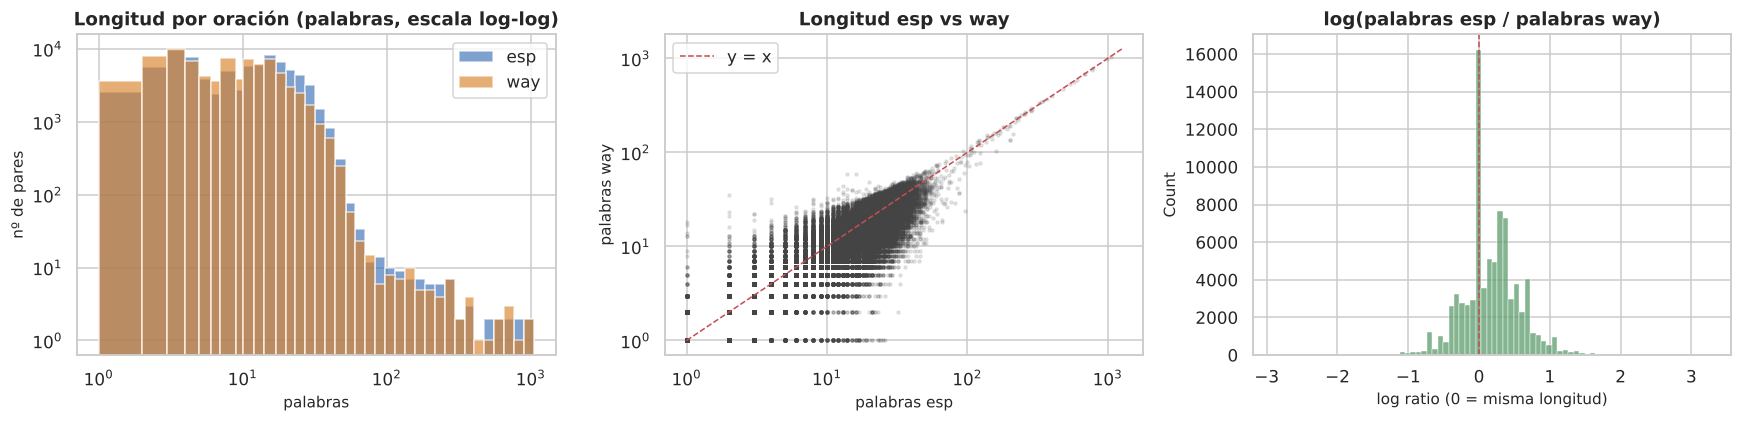

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# (a) Distribución de longitud en palabras
bins = np.unique(np.logspace(0, np.log10(df[["n_pal_esp", "n_pal_way"]].max().max() + 1), 45).astype(int))
for col, c in (("n_pal_esp", "#3b6fb6"), ("n_pal_way", "#d9822b")):
    axes[0].hist(df[col].clip(lower=1), bins=bins, alpha=.65, label=col[-3:], color=c)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set(title="Longitud por oración (palabras, escala log-log)", xlabel="palabras", ylabel="nº de pares")
axes[0].legend()

# (b) Longitud esp vs way
axes[1].scatter(df.n_pal_esp.clip(lower=1), df.n_pal_way.clip(lower=1), s=4, alpha=.12, color="#444")
lim = [1, df[["n_pal_esp", "n_pal_way"]].max().max() * 1.2]
axes[1].plot(lim, lim, "r--", lw=1, label="y = x")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set(title="Longitud esp vs way", xlabel="palabras esp", ylabel="palabras way"); axes[1].legend()

# (c) Ratio de longitud
sns.histplot(df.log_ratio, bins=80, ax=axes[2], color="#5b9b6b")
axes[2].axvline(0, color="r", ls="--", lw=1)
axes[2].set(title="log(palabras esp / palabras way)", xlabel="log ratio (0 = misma longitud)")
plt.tight_layout(); plt.show()

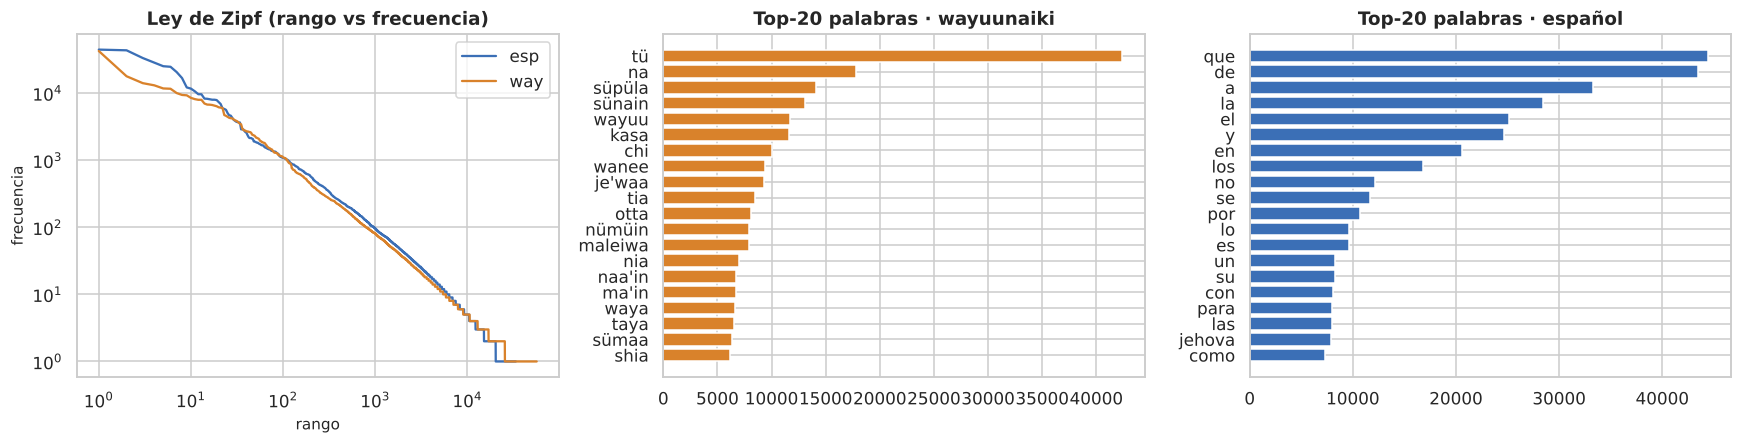

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# (a) Zipf
for col, c in (("esp", "#3b6fb6"), ("way", "#d9822b")):
    freqs = np.array(sorted(vocab[col].values(), reverse=True))
    axes[0].loglog(np.arange(1, len(freqs) + 1), freqs, label=col, color=c)
axes[0].set(title="Ley de Zipf (rango vs frecuencia)", xlabel="rango", ylabel="frecuencia"); axes[0].legend()

# (b) Top-20 palabras de way
t = pd.Series(dict(vocab["way"].most_common(20)))[::-1]
axes[1].barh(t.index, t.values, color="#d9822b"); axes[1].set_title("Top-20 palabras · wayuunaiki")

# (c) Top-20 palabras de esp
t = pd.Series(dict(vocab["esp"].most_common(20)))[::-1]
axes[2].barh(t.index, t.values, color="#3b6fb6"); axes[2].set_title("Top-20 palabras · español")
plt.tight_layout(); plt.show()

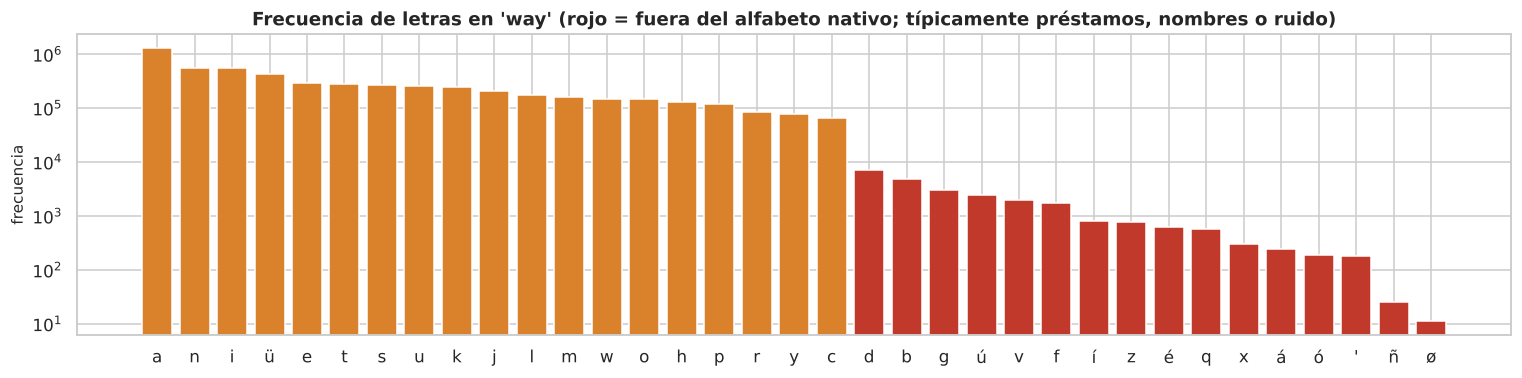

In [12]:
# Frecuencia de letras en wayuunaiki
fig, ax = plt.subplots(figsize=(14, 3.6))
lo = pd.Series(Counter(ch.lower() for s in df.way for ch in s if ch.isalpha())).sort_values(ascending=False)
colors = ["#d9822b" if ch in core_letters else "#c0392b" for ch in lo.index]
ax.bar(lo.index, lo.values, color=colors)
ax.set(title="Frecuencia de letras en 'way' (rojo = fuera del alfabeto nativo; típicamente préstamos, nombres o ruido)",
       ylabel="frecuencia"); ax.set_yscale("log")
plt.tight_layout(); plt.show()

**Longitud a lo largo del archivo.** Como los datos *no están barajados*, graficar el promedio móvil por posición de fila revela bloques de distinta procedencia (se usa en 5.3).

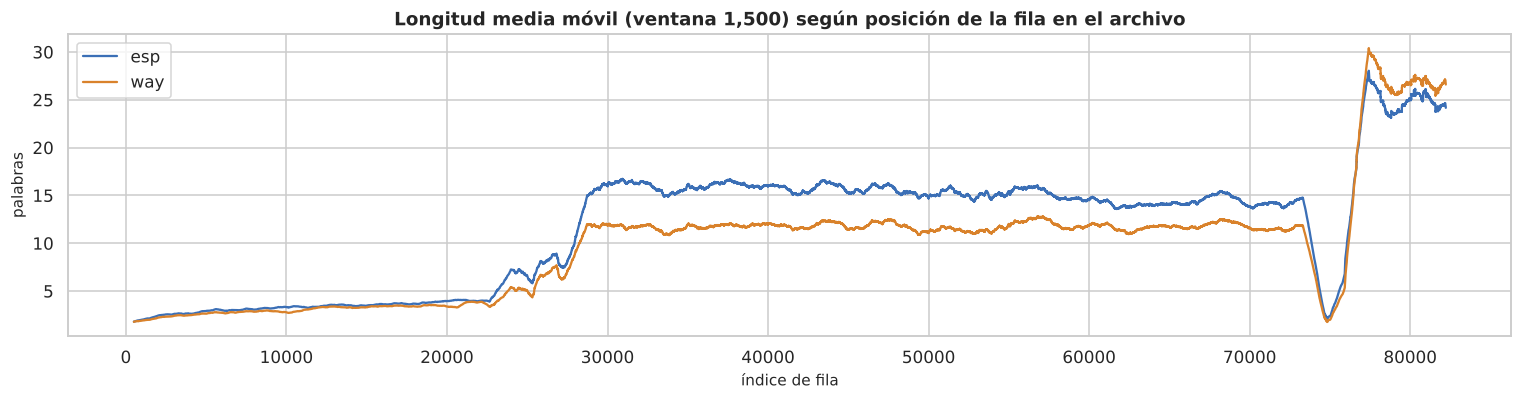

In [13]:
w = 1500
roll = df[["n_pal_esp", "n_pal_way"]].rolling(w, min_periods=w // 3).mean()
fig, ax = plt.subplots(figsize=(14, 3.8))
ax.plot(roll.index, roll.n_pal_esp, label="esp", color="#3b6fb6")
ax.plot(roll.index, roll.n_pal_way, label="way", color="#d9822b")
ax.set(title=f"Longitud media móvil (ventana {w:,}) según posición de la fila en el archivo",
       xlabel="índice de fila", ylabel="palabras"); ax.legend()
plt.tight_layout(); plt.show()

## 5. Problemas de calidad de datos

### 5.1 Nulos, vacíos y espacios

In [14]:
rows = []
for col in ("esp", "way"):
    s = df[col]
    rows.append({"columna": col,
                 "nulos (NaN)": int(s.isna().sum()),
                 "cadena vacía / solo espacios": int((s.str.strip() == "").sum()),
                 "espacios al inicio/fin": int((s != s.str.strip()).sum()),
                 "espacios dobles": int(s.str.contains(r"\s{2,}").sum()),
                 "saltos de línea / tabs": int(s.str.contains(r"[\n\r\t]").sum()),
                 "contiene dígitos": int(s.str.contains(r"\d").sum()),
                 "no está en NFC (unicode)": int((s.map(lambda x: unicodedata.normalize("NFC", x)) != s).sum())})
display(pd.DataFrame(rows).set_index("columna"))
print("NaN que pandas habría creado por defecto en todos los archivos:", inv.NaN_pandas_por_defecto.sum())

,nulos (NaN),cadena vacía / solo espacios,espacios al inicio/fin,espacios dobles,saltos de línea / tabs,contiene dígitos,no está en NFC (unicode)
columna,,,,,,,
esp,0,0,1,137,0,142,0
way,0,0,1,223,0,92,0


NaN que pandas habría creado por defecto en todos los archivos: 0


✅ No hay nulos ni vacíos. Los únicos problemas son menores (espacios dobles/dígitos); los dígitos se revisan en 5.4 porque en `way` pueden ser errores tipográficos (`wa1ma`).

### 5.2 Duplicados y relaciones muchos-a-muchos

Pares exactos duplicados : 2,188 (2.66%)
Fuente (esp) repetida    : 6,496 (7.90%)
Destino (way) repetido   : 6,586 (8.01%)



esp con >1 traducción distinta: 3,536 (máx 57)
way con >1 fuente distinta     : 3,167 (máx 94)


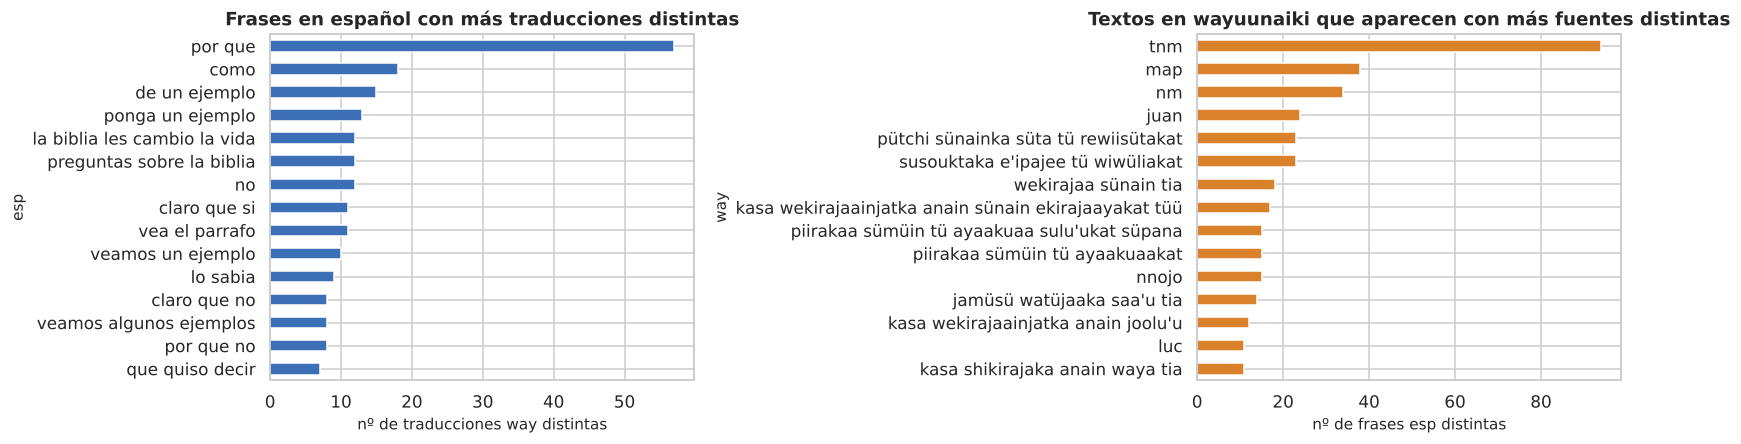

In [15]:
n = len(df)
dup_pair = df.duplicated(["esp", "way"]).sum()
dup_esp  = df.esp.duplicated().sum()
dup_way  = df.way.duplicated().sum()
print(f"Pares exactos duplicados : {dup_pair:,} ({100*dup_pair/n:.2f}%)")
print(f"Fuente (esp) repetida    : {dup_esp:,} ({100*dup_esp/n:.2f}%)")
print(f"Destino (way) repetido   : {dup_way:,} ({100*dup_way/n:.2f}%)")

m_e = df.groupby("esp").way.nunique()
m_w = df.groupby("way").esp.nunique()
print(f"\nesp con >1 traducción distinta: {(m_e > 1).sum():,} (máx {m_e.max()})")
print(f"way con >1 fuente distinta     : {(m_w > 1).sum():,} (máx {m_w.max()})")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
m_e.sort_values(ascending=False).head(15)[::-1].plot.barh(ax=axes[0], color="#3b6fb6")
axes[0].set(title="Frases en español con más traducciones distintas", xlabel="nº de traducciones way distintas")
m_w.sort_values(ascending=False).head(15)[::-1].plot.barh(ax=axes[1], color="#d9822b")
axes[1].set(title="Textos en wayuunaiki que aparecen con más fuentes distintas", xlabel="nº de frases esp distintas")
plt.tight_layout(); plt.show()

In [16]:
# Ejemplos de ambigüedad legítima (diccionario) vs sospechosa
ex = df[df.esp == "por que"].way.value_counts().head(6)
print("Traducciones de «por que»:"); display(ex.to_frame("veces"))
print("Fuentes distintas con el mismo destino «tnm»:")
display(df[df.way == "tnm"].esp.head(5).to_frame())

Traducciones de «por que»:


,veces
way,
sulu'u jamüin,5
aka jamüin,4
jamüsü,2
jamüsü naainjaka tia,2
jamüsü cho'ujaaka tia,2
tnm,2


Fuentes distintas con el mismo destino «tnm»:


,esp
34572,y nosotros
34643,veamos un ejemplo
34712,proverbios declara te has mostrado desanimado en el dia de la angustia
45857,si jesus no hubiera resucitado nada de esto seria posible
46091,yo soy jehova


**Lectura:** los duplicados exactos son pocos pero existen; el problema mayor es **muchos-a-muchos**: una misma frase española con hasta decenas de traducciones, y destinos como `tnm`/`map` repetidos para decenas de fuentes distintas (artefactos; ver 5.5). Esto introduce ruido en la señal de entrenamiento y sesga las métricas si las repeticiones caen en test.

### 5.3 Heterogeneidad de fuentes y desbalance
El archivo es una concatenación de bloques con estilos muy distintos. Definimos **segmentos heurísticos** a partir de rasgos del texto y de la posición:

- **C · Con formato**: el español tiene mayúsculas o puntuación.
- Entre los restantes (todo minúscula, sin puntuación), buscamos un **punto de cambio** (CUSUM de mínima varianza) en la longitud media → **A · Léxico/frases cortas** vs **B · Oraciones normalizadas**.

In [17]:
def formatted_mask(d):
    return d.esp.str.contains(r"[A-ZÁÉÍÓÚÑ]") | d.esp.str.contains(r"[.,;:¿?¡!]")

def changepoint(x, margin=500):
    x = np.asarray(x, float); n = len(x)
    cs, cs2 = np.cumsum(x), np.cumsum(x ** 2)
    k = np.arange(margin, n - margin)
    sse = (cs2[k - 1] - cs[k - 1] ** 2 / k) + ((cs2[-1] - cs2[k - 1]) - (cs[-1] - cs[k - 1]) ** 2 / (n - k))
    return int(k[np.argmin(sse)])

fmt = formatted_mask(df)
norm_idx = df.index[~fmt]
cp = changepoint(np.log1p(df.loc[norm_idx, "n_pal_esp"].values))
boundary = norm_idx[cp]
print(f"Filas con formato (C): {fmt.sum():,}  | primera fila con formato: {fmt.idxmax():,}")
print(f"Punto de cambio entre A y B detectado en la fila {boundary:,}")

SEG = {"A": "A · Léxico / frases cortas", "B": "B · Oraciones normalizadas", "C": "C · Texto con formato"}
df["segmento"] = np.where(fmt, SEG["C"], np.where(df.index < boundary, SEG["A"], SEG["B"]))
seg_order = list(SEG.values())

seg_stats = (df.groupby("segmento")
               .agg(filas=("esp", "size"), pal_esp_media=("n_pal_esp", "mean"), pal_way_media=("n_pal_way", "mean"),
                    pal_esp_mediana=("n_pal_esp", "median"), ratio_mediano=("ratio_pal", "median"))
               .reindex(seg_order))
seg_stats["% del corpus"] = (100 * seg_stats.filas / len(df)).round(1)
display(seg_stats.round(2))

Filas con formato (C): 7,494  | primera fila con formato: 74,546
Punto de cambio entre A y B detectado en la fila 27,230


,filas,pal_esp_media,pal_way_media,pal_esp_mediana,ratio_mediano,% del corpus
segmento,,,,,,
A · Léxico / frases cortas,27230,4.01,3.53,3.0,1.00,33.1
B · Oraciones normalizadas,47494,14.78,11.44,14.0,1.25,57.8
C · Texto con formato,7494,22.44,23.94,19.0,0.96,9.1


% de filas de cada segmento cuyo texto en español contiene los términos:


,religioso (jehova|biblia|dios|jesus),jurídico (ley|constituci|estado|senado|derech),cotidiano (casa|comer|agua|niño|madre)
segmento,,,
A · Léxico / frases cortas,0.2,0.3,2.3
B · Oraciones normalizadas,36.3,1.4,3.9
C · Texto con formato,17.5,4.2,10.9


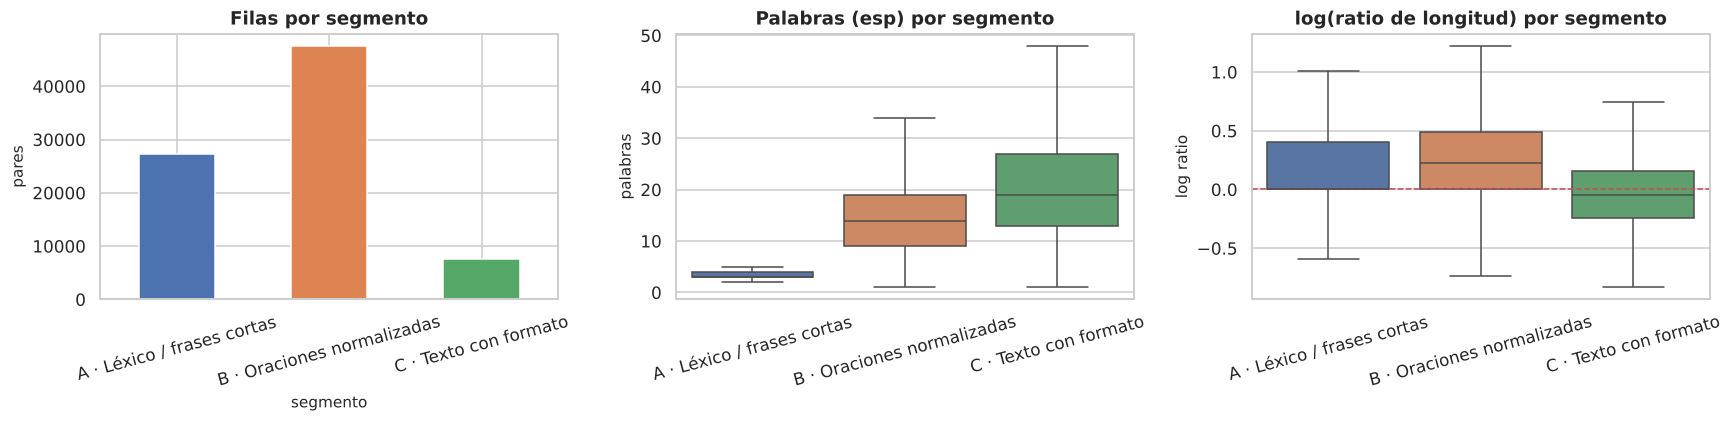

In [18]:
# Sondeo de temática por segmento (hipótesis, no verdad absoluta)
probes = {"religioso (jehova|biblia|dios|jesus)": r"jehova|biblia|dios|jesus|cristo",
          "jurídico (ley|constituci|estado|senado|derech)": r"\bley\b|constituci|estado|senado|derech|jur[ií]dic",
          "cotidiano (casa|comer|agua|niño|madre)": r"\bcasa\b|comer|\bagua\b|ni[ñn]o|madre|padre"}
pr = pd.DataFrame({k: df.groupby("segmento").esp.apply(lambda s: round(100 * s.str.lower().str.contains(v).mean(), 1))
                   for k, v in probes.items()}).reindex(seg_order)
print("% de filas de cada segmento cuyo texto en español contiene los términos:")
display(pr)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
seg_stats["filas"].plot.bar(ax=axes[0], color=sns.color_palette("deep")[:3], rot=15)
axes[0].set(title="Filas por segmento", ylabel="pares")
sns.boxplot(data=df.assign(l=df.n_pal_esp.clip(lower=1)), x="segmento", y="l", order=seg_order, ax=axes[1],
            showfliers=False, palette="deep")
axes[1].set(title="Palabras (esp) por segmento", xlabel="", ylabel="palabras"); axes[1].tick_params(axis="x", rotation=15)
sns.boxplot(data=df, x="segmento", y="log_ratio", order=seg_order, ax=axes[2], showfliers=False, palette="deep")
axes[2].axhline(0, color="r", ls="--", lw=1)
axes[2].set(title="log(ratio de longitud) por segmento", xlabel="", ylabel="log ratio"); axes[2].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

**Desbalance de vocabulario / frecuencia** (análogo al desbalance de clases):

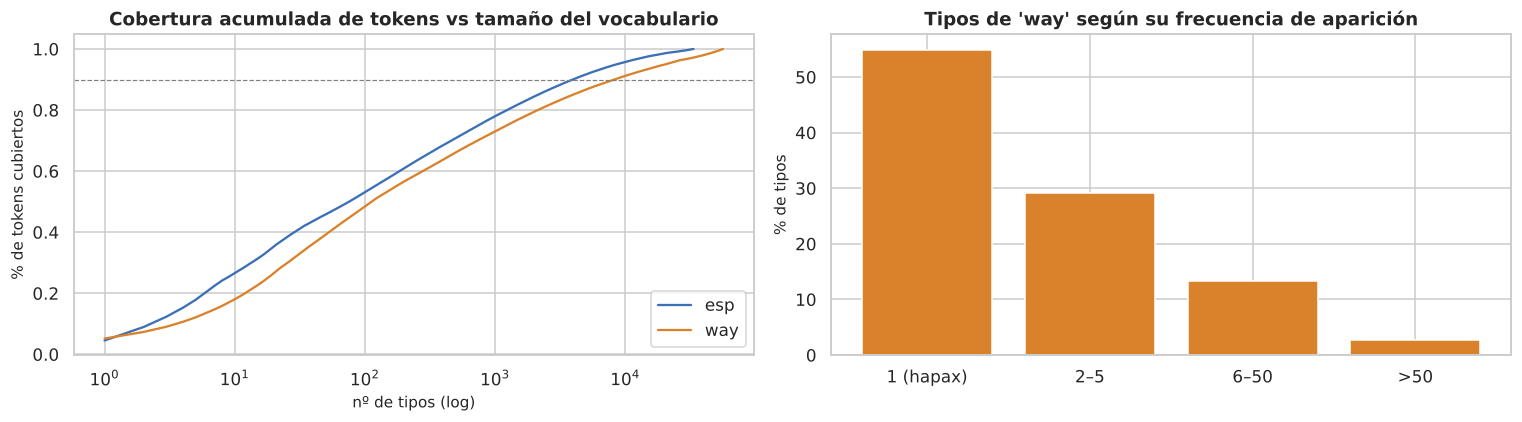

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for col, c in (("esp", "#3b6fb6"), ("way", "#d9822b")):
    freqs = np.array(sorted(vocab[col].values(), reverse=True))
    cum = np.cumsum(freqs) / freqs.sum()
    axes[0].plot(np.arange(1, len(cum) + 1), cum, label=col, color=c)
axes[0].set_xscale("log"); axes[0].axhline(.9, ls="--", color="gray", lw=.8)
axes[0].set(title="Cobertura acumulada de tokens vs tamaño del vocabulario", xlabel="nº de tipos (log)", ylabel="% de tokens cubiertos")
axes[0].legend()

freq_of_freq = pd.Series(Counter(vocab["way"].values())).sort_index()
share = pd.Series({"1 (hapax)": freq_of_freq.loc[1], "2–5": freq_of_freq.loc[2:5].sum(),
                   "6–50": freq_of_freq.loc[6:50].sum(), ">50": freq_of_freq.loc[51:].sum()})
axes[1].bar(share.index, 100 * share / share.sum(), color="#d9822b")
axes[1].set(title="Tipos de 'way' según su frecuencia de aparición", ylabel="% de tipos")
plt.tight_layout(); plt.show()

**Lectura:** el corpus tiene **tres regímenes muy distintos** (palabras sueltas, oraciones largas estilo publicación religiosa, y texto formal con mayúsculas/puntuación). Los modelos entrenados con mezcla uniforme estarán dominados por el segmento B (el más grande), y las métricas globales ocultarán el rendimiento en A y C. Además, una gran parte del vocabulario de `way` son *hapax* (aparecen una sola vez): problema típico de lenguas de pocos recursos y de lenguas aglutinantes.

### 5.4 Inconsistencias de normalización y ruido de caracteres

In [20]:
def pct(mask_fn):
    return df.groupby("segmento").apply(lambda g: round(100 * mask_fn(g).mean(), 1)).reindex(seg_order)

norm_tbl = pd.DataFrame({
    "empieza con mayúscula (esp)": pct(lambda g: g.esp.str[0].str.isupper()),
    "tiene puntuación (esp)":      pct(lambda g: g.esp.str.contains(r"[.,;:¿?¡!]")),
    "tiene tildes (esp)":          pct(lambda g: g.esp.str.contains(r"[áéíóú]")),
    "tiene ñ (esp)":               pct(lambda g: g.esp.str.contains("ñ")),
    "tiene puntuación (way)":      pct(lambda g: g.way.str.contains(r"[.,;:¿?¡!]")),
    "tiene mayúsculas (way)":      pct(lambda g: g.way.str.contains(r"[A-ZÜ]")),
})
print("% de filas con cada rasgo, por segmento →  los segmentos A y B están 'aplanados' (minúsculas, sin tildes ni puntuación):")
display(norm_tbl)

% de filas con cada rasgo, por segmento →  los segmentos A y B están 'aplanados' (minúsculas, sin tildes ni puntuación):


,empieza con mayúscula (esp),tiene puntuación (esp),tiene tildes (esp),tiene ñ (esp),tiene puntuación (way),tiene mayúsculas (way)
segmento,,,,,,
A · Léxico / frases cortas,0.0,0.0,0.0,0.0,0.0,0.0
B · Oraciones normalizadas,0.0,0.0,0.1,0.0,0.0,0.1
C · Texto con formato,84.7,97.3,85.6,18.1,96.6,99.5


In [21]:
# (1) ñ corrompida: en los segmentos normalizados la ñ fue sustituida por un espacio («ni os», «sue o», «compa eros»)
n_corrupt = re.compile(r"\b(?:ni os?|ni as?|sue os?|compa eros?|compa eras?|ma ana|espa ol\w*|se or\w*|"
                       r"ense ar\w*|dise o\w*|due o\w*|peque o\w*|ba arse|a os?|a o)\b")
mask_n = ~fmt & df.esp.str.contains(n_corrupt)
print(f"Filas de segmentos normalizados con 'ñ→espacio' (heurística de palabras comunes): {mask_n.sum():,}")
display(df.loc[mask_n, ["esp", "way"]].sample(6, random_state=3))
print("Filas esp con 'ñ' real en segmentos A/B:", int((~fmt & df.esp.str.contains('ñ')).sum()),
      " | en C:", int((fmt & df.esp.str.contains('ñ')).sum()))

Filas de segmentos normalizados con 'ñ→espacio' (heurística de palabras comunes): 2,770


,esp,way
36526,lejos de sentir envidia las otras ovejas de jesus se alegran por sus compa eros ungidos,talatüsü naa'in sutuma tü nüküjakat jesuu namüin na chainjanakana iipünaa
54559,poco despues de la gripe espa ola acabo con la vida de decenas de millones de personas,jamüsüja'a süchikijee wainma ma'in wayuu o'uwo'utka sutuma tü gripe espa ola münakat
36420,ha caido la noche comienza el de nisan del a o,aipo'uupa so'u nisan juyaka eejachi jesuu namaa na nikirajüinkana sünain ekeraajaa tü ...
30069,la resurreccion fue precisamente lo que dio a los discipulos el valor de dar testimoni...,ja'itainna müliain ma'in na nikirajüinkana jesuu ayatshi'iya meimmoluin naya sünain ak...
71005,empece en este servicio el de enero de a la edad de a os,pürekutsootshi taya mapa o'ttüshi taya eneero'u wanaa sümaa touyase
56490,durante treinta y tres a os los judios soportaron el yugo romano,alatüsü juya süchikijee tia sümaa ayatüin naluwataain na romaanokana naa'u na judiokana


Filas esp con 'ñ' real en segmentos A/B: 5  | en C: 1360


In [22]:
# (2) Variantes del apóstrofo / saltillo en 'way' (la marca de glotal es parte de la ortografía)
cands = {"'": "U+0027 apóstrofo recto", "’": "U+2019 comilla curva der.", "‘": "U+2018 comilla curva izq.",
         "ʼ": "U+02BC letra modificadora", "ꞌ": "U+A78C saltillo minúscula", "Ꞌ": "U+A78B saltillo mayúscula",
         "´": "U+00B4 acento agudo", "`": "U+0060 tilde grave"}
ap = pd.DataFrame({"caracter": list(cands), "descripcion": list(cands.values()),
                   "ocurrencias": [df.way.str.count(re.escape(c)).sum() for c in cands],
                   "filas": [df.way.str.contains(re.escape(c)).sum() for c in cands]})
ap = ap[ap.ocurrencias > 0].reset_index(drop=True)
display(ap)
print("Filas con 2 o más variantes distintas mezcladas:",
      int((df.way.map(lambda s: sum(c in s for c in cands)) >= 2).sum()))

,caracter,descripcion,ocurrencias,filas
0,',U+0027 apóstrofo recto,170366,61241
1,’,U+2019 comilla curva der.,1045,676
2,‘,U+2018 comilla curva izq.,308,263
3,ꞌ,U+A78C saltillo minúscula,87,67
4,Ꞌ,U+A78B saltillo mayúscula,90,75
5,´,U+00B4 acento agudo,4,2


Filas con 2 o más variantes distintas mezcladas: 408


In [23]:
# (3) Ruido tipo OCR / tipográfico en 'way': dígitos dentro de palabras, mayúsculas internas, símbolos raros
patterns = {
    "dígito pegado a letra (wa1ma)":         r"[A-Za-zÜü]\d|\d[A-Za-zÜü]",
    "mayúscula dentro de palabra (kasaÍii)": rf"[a-züáéíóú{re.escape(APOS)}][A-ZÁÉÍÓÚÜ]",
    "caracteres raros (√ * ~ · _ Ø)":        r"[√*~·_Ø]",
    "corchetes / paréntesis":                r"[\[\]()]",
    "comillas tipográficas (“ ” ‘)":         r"[“”‘]",
    "raya larga (—) / guion largo (–)":      r"[—–]",
}
noise = pd.DataFrame({"filas way": {k: df.way.str.contains(v).sum() for k, v in patterns.items()},
                      "filas esp": {k: df.esp.str.contains(v).sum() for k, v in patterns.items()}})
display(noise)
display(df.loc[df.way.str.contains(patterns["dígito pegado a letra (wa1ma)"]), ["way"]].head(5))
display(df.loc[df.way.str.contains(patterns["mayúscula dentro de palabra (kasaÍii)"]), ["way"]].head(5))

,filas way,filas esp
dígito pegado a letra (wa1ma),81,76
mayúscula dentro de palabra (kasaÍii),235,10
caracteres raros (√ * ~ · _ Ø),19,7
corchetes / paréntesis,69,90
comillas tipográficas (“ ” ‘),1285,15
raya larga (—) / guion largo (–),1215,1279


,way
75941,Kolonpiana wayuukanairua naa: 1. Sa'uje jemelii: a) Kolonpianashi ekai: kolonpianain n...
75954,Ayawatunüinjatü akua'ipa tüü aksiones populales münaka süchirua a'imaja sükua'ipa wayu...
76056,Saa'u taapinnüin nütüma chi Wasenyotsekai Jesucristo saa'u sülü'ülüin takalia süpüla o...
76281,Süküjünakalaka tamüin süchiki sünain shi'itaanüitpain nejeetse chi Maleiwakai shi'ipo'...
76282,"Tü wayuu e'itaanakat anain tü nejeetsekat, müsü mayaa:Na'akajee na ni'irukukana Judá, ..."


,way
75923,Tüü sükoroloko wayuu sümaiwajatü jee müsüya tüü süpülajatka wayuu süpushuaya shia müle...
75924,Tüü mma kalaulajanaka. Kajütsü amünii süpüla. süchajain sükua'ipa kasa eekai cho'ujain...
75952,Napushua naa wayuukana eeshii süpula nachuntüin tüü aksion tutela münaka süpula nasaka...
76200,"sünain nümüin tamüin: “Tü pi'reetkat joolu'u, anakaja müleka püshajüle shia sulu'u wan..."
76359,Sha'watüshi chi kayuushikai sotpa'amüin tü palaakat.Chi wanülüü shirokujeejachikai pal...


In [24]:
# (4) Texto «pegado» (sin espacio tras el punto → posibles fusiones de oraciones)
glued = r"[a-zñáéíóú][.?!][A-ZÁÉÍÓÚ]"
print("Filas con oraciones pegadas (esp):", df.esp.str.contains(glued).sum(),
      "| (way):", df.way.str.contains(glued).sum())
display(df[df.esp.str.contains(glued)].esp.head(3).str[:200].to_frame())

Filas con oraciones pegadas (esp): 732 | (way): 727


,esp
75960,Esto que escribimos es para que nuestra común alegría sea completa.I. Luz en medio de ...
75973,"Pero quien lo aborrece, vive y camina en tinieblas, sin saber adónde va, porque las ti..."
75979,Pero el mundo y sus pasiones se desvanecen; solo el que hace la voluntad de Dios perma...


**Lectura:** los segmentos A y B pasaron por una normalización agresiva (minúsculas, sin tildes ni puntuación) que, además, **destruyó la `ñ`** (se convirtió en espacio, creando "palabras" falsas como `ni os`). El segmento C conserva el formato original. El **saltillo** aparece con hasta 6 codificaciones distintas, lo que fragmenta el vocabulario (la misma palabra con `'` y con `’` cuenta como dos tipos) y genera tokens distintos para la misma forma. Hay además ruido tipográfico puntual (dígitos, mayúsculas internas, símbolos).

### 5.5 Outliers y posibles desalineaciones

Umbral IQR (en log) → esp > 122 palabras | way > 108 palabras
Outliers de longitud (IQR): 59 (0.07%)
Pares con esp > 100 palabras: 66 | > 200: 29 | máx: 1049
Outliers del ratio de longitud (|z robusto| > 4): 559 (0.68%)
   · way mucho más corto que esp (z > 4): 434 | way mucho más largo (z < -4): 125


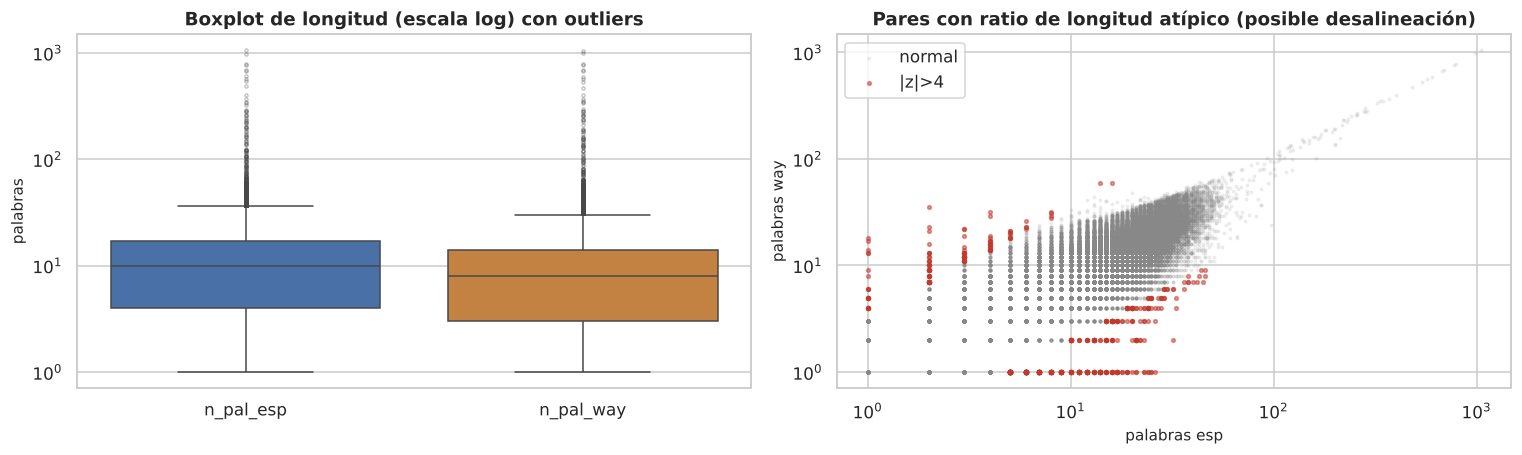

In [25]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - k * i, q3 + k * i

lo, hi_e = iqr_bounds(np.log1p(df.n_pal_esp)); hi_e = np.expm1(hi_e)
lo, hi_w = iqr_bounds(np.log1p(df.n_pal_way)); hi_w = np.expm1(hi_w)
print(f"Umbral IQR (en log) → esp > {hi_e:.0f} palabras | way > {hi_w:.0f} palabras")

out_len = df[(df.n_pal_esp > hi_e) | (df.n_pal_way > hi_w)]
print(f"Outliers de longitud (IQR): {len(out_len):,} ({100*len(out_len)/len(df):.2f}%)")
print(f"Pares con esp > 100 palabras: {(df.n_pal_esp > 100).sum()} | > 200: {(df.n_pal_esp > 200).sum()} | máx: {df.n_pal_esp.max()}")

# Outliers del ratio de longitud con z-score robusto (mediana/MAD)
med = df.log_ratio.median(); mad = (df.log_ratio - med).abs().median() * 1.4826
df["z_ratio"] = (df.log_ratio - med) / mad
out_ratio = df[df.z_ratio.abs() > 4]
print(f"Outliers del ratio de longitud (|z robusto| > 4): {len(out_ratio):,} ({100*len(out_ratio)/len(df):.2f}%)")
print(f"   · way mucho más corto que esp (z > 4): {(df.z_ratio > 4).sum():,} | way mucho más largo (z < -4): {(df.z_ratio < -4).sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
sns.boxplot(data=df[["n_pal_esp", "n_pal_way"]].clip(lower=1).melt(var_name="idioma", value_name="palabras"),
            x="idioma", y="palabras", ax=axes[0], showfliers=True, flierprops=dict(markersize=2, alpha=.3), palette=["#3b6fb6", "#d9822b"])
axes[0].set_yscale("log"); axes[0].set(title="Boxplot de longitud (escala log) con outliers", xlabel="")
ok = df.z_ratio.abs() <= 4
axes[1].scatter(df.n_pal_esp[ok].clip(lower=1), df.n_pal_way[ok].clip(lower=1), s=3, alpha=.1, color="#888", label="normal")
axes[1].scatter(df.n_pal_esp[~ok].clip(lower=1), df.n_pal_way[~ok].clip(lower=1), s=6, alpha=.5, color="#c0392b", label="|z|>4")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].legend()
axes[1].set(title="Pares con ratio de longitud atípico (posible desalineación)", xlabel="palabras esp", ylabel="palabras way")
plt.tight_layout(); plt.show()

In [26]:
# Destinos de 1 token para fuentes largas → artefactos (abreviaturas bíblicas, códigos…) en lugar de traducciones
short_tgt = df[(df.n_pal_way == 1) & (df.n_pal_esp >= 5)]
print(f"Pares con destino de 1 palabra y fuente ≥5 palabras: {len(short_tgt):,}")
display(short_tgt.way.value_counts().head(15).to_frame("veces").T)
display(short_tgt[["esp", "way"]].sample(6, random_state=2))

print("\nEjemplos con desalineación evidente (esp ≫ way o way ≫ esp):")
display(df[df.z_ratio > 6].sort_values("z_ratio", ascending=False)[["esp", "way", "n_pal_esp", "n_pal_way"]].head(4))
display(df[df.z_ratio < -6].sort_values("z_ratio")[["esp", "way", "n_pal_esp", "n_pal_way"]].head(4))

same = df[df.esp.str.lower().str.strip() == df.way.str.lower().str.strip()]
print(f"\nPares con esp == way (copias; nombres propios, números, préstamos o error): {len(same):,}")
display(same.esp.value_counts().head(10).to_frame("veces").T)

Pares con destino de 1 palabra y fuente ≥5 palabras: 272


way,tnm,map,nm,cor,juan,luc,heb,sal,sam,ped,ex,filip,rey,prov,aluwataaushikana
veces,67,28,26,11,11,10,8,6,4,4,4,4,4,4,3


,esp,way
42049,no habra mas opresion ni pobreza ni hambre,nm
22617,bollos de maiz cariaco seco,yaja
43921,hemos buscado y el nos da descanso,nm
23978,la que se desplaza desde el oeste,wopumüinkuwolu
42542,necesitamos cambiar nuestro punto de vista,sam
61701,cumplieron la promesa que se habian hecho resulte jehova mismo estar entre yo y tu y e...,tnm



Ejemplos con desalineación evidente (esp ≫ way o way ≫ esp):


,esp,way,n_pal_esp,n_pal_way
69252,jesus mismo convirtio el agua en vino en una boda y pablo le aconsejo a timoteo que to...,juan,26,1
30337,escudri ar el corazon no exige un examen medico del organo literal que en setenta u oc...,nm,25,1
61701,cumplieron la promesa que se habian hecho resulte jehova mismo estar entre yo y tu y e...,tnm,25,1
37569,por que debemos tener cuidado cuando alguien se pone a hablar de asuntos que la biblia...,nm,24,1


,esp,way,n_pal_esp,n_pal_way
39024,versiculo,wersiikulo eejatü wanee atkawaa chaa iipünaa eejachire nütkaain chi aapiee müle'oshika...,1,18
60609,lea lucas,eeshii süpüla wawaraijaain naa'u wakolojuin wanee kasa neküin eeshii süpüla wakaaliinj...,2,35
57249,como,nekirajüinjana naya sünain jamüin nünüiki maleiwa süchiki tia makat jee müsia nekirajü...,1,17
61585,como,nnojo wayouktajaain sümaa tü a'yatawaa naapakat je'waa wamüin otta we'itaa waa'in süna...,1,14



Pares con esp == way (copias; nombres propios, números, préstamos o error): 231


esp,watch tower bible and tract society of pennsylvania,mateo,salmo,santiago,isaias,cinco cuestiones dignas de analisis,lucas,estados unidos,george,nicole
veces,62,6,3,3,3,2,2,2,2,2


**Lectura:** hay una cola de **pares probablemente mal alineados**: destinos de una sola palabra (`tnm`, `map`, `nm`, `mar`…, que parecen abreviaturas de publicaciones o referencias) enfrentados a oraciones completas, y casos donde el texto en `way` es varias veces más largo/corto de lo esperable. También hay unas pocas entradas **extremadamente largas** (cientos de palabras) que corresponden a párrafos completos y no a oraciones.

### 5.6 Fuga de datos entre particiones (train / dev / test)
Un buen split no debe compartir pares (ni siquiera la misma frase de origen) entre entrenamiento y evaluación.

In [27]:
def nkey(s):  # clave "normalizada": minúsculas, sin puntuación/tildes ni espacios múltiples
    s = unicodedata.normalize("NFKD", s.lower())
    s = "".join(c for c in s if not unicodedata.combining(c))
    return re.sub(r"[^a-zñ0-9 ]+", "", re.sub(r"\s+", " ", s)).strip()

rows = []
for fam in ["completo", "completo_v2", "sin_dict", "sin_dic_v2"]:
    sub = inv[inv.familia == fam].set_index("split").archivo
    if "train" not in sub.index:
        continue
    tr = data[sub["train"]]
    tr_pairs, tr_esp, tr_way = key(tr), set(tr.esp), set(tr.way)
    tr_esp_n = {nkey(x) for x in tr.esp}
    for sp in ("dev", "test"):
        if sp not in sub.index:
            rows.append({"familia": fam, "split": sp, "filas": "AUSENTE"}); continue
        ev = data[sub[sp]]
        rows.append({"familia": fam, "split": sp, "filas": len(ev),
                     "% pares exactos en train":    round(100 * np.mean([p in tr_pairs for p in zip(ev.esp, ev.way)]), 2),
                     "% fuente (esp) vista en train": round(100 * ev.esp.isin(tr_esp).mean(), 2),
                     "% destino (way) visto en train": round(100 * ev.way.isin(tr_way).mean(), 2),
                     "% fuente norm. en train":      round(100 * ev.esp.map(nkey).isin(tr_esp_n).mean(), 2)})
leak = pd.DataFrame(rows).set_index(["familia", "split"])
display(leak)

# Fuga entre dev y test (si se afina hiperparámetros en dev y se reporta en test, tampoco deben solaparse)
rows2 = []
for fam in ["completo", "completo_v2", "sin_dict", "sin_dic_v2"]:
    sub = inv[inv.familia == fam].set_index("split").archivo
    if {"dev", "test"} <= set(sub.index):
        dv_, te_ = data[sub["dev"]], data[sub["test"]]
        rows2.append({"familia": fam, "pares dev∩test": len(key(dv_) & key(te_)),
                      "% del test": round(100 * len(key(dv_) & key(te_)) / len(key(te_)), 2),
                      "fuentes esp dev∩test": len(set(dv_.esp) & set(te_.esp))})
display(pd.DataFrame(rows2).set_index("familia"))

filas  % pares exactos en train  % fuente (esp) vista en train  % destino (way) visto en train  % fuente norm. en train
familia     split                                                                                                                         
completo    dev     7596                      3.75                          11.49                           11.41                    12.51
            test    7596                      4.13                          12.52                           11.77                    13.22
completo_v2 dev     8222                      3.36                          10.23                           10.68                    11.09
            test    8222                      3.79                          11.58                           11.58                    12.52
sin_dict    dev      138                      6.52                          17.39                            9.42                    21.74
            test     138                      7.25                          16.67                            8.70                    18.84
sin_dic_v2  dev      763                      1.83                           3.15                            3.01                     3.54
            test     764                      1.57                           3.14                            3.40                     3.27

,pares dev∩test,% del test,fuentes esp dev∩test
familia,,,
completo,69,0.92,160
completo_v2,58,0.71,173
sin_dict,0,0.00,3
sin_dic_v2,4,0.52,6


,A · Léxico / frases cortas,B · Oraciones normalizadas,C · Texto con formato,filas
completo_v2_train,33.4,57.5,9.1,65774
completo_v2_dev,32.5,58.0,9.5,8222
completo_v2_test,32.9,58.3,8.8,8222
completo_train,36.1,62.2,1.7,60767
completo_dev,35.6,62.8,1.6,7596
completo_test,35.7,62.8,1.5,7596


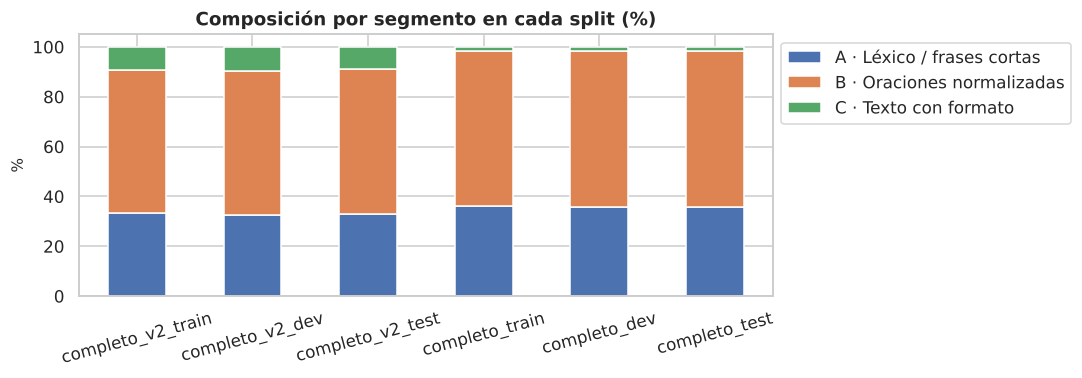

Longitud (palabras esp) por split — completo:


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
dev,7596.0,11.02,8.70,1.0,4.0,9.0,16.0,66.0
test,7596.0,10.87,8.61,1.0,4.0,9.0,16.0,161.0
train,60767.0,10.81,8.79,1.0,4.0,9.0,16.0,213.0


In [28]:
# Composición por segmento en cada split (¿está estratificado?). Se mapea cada par a su segmento de origen.
origin = (df.drop_duplicates(["esp", "way"]).set_index(["esp", "way"]).segmento)
def seg_of(d):
    idx = pd.MultiIndex.from_arrays([d.esp, d.way])
    return pd.Series(origin.reindex(idx).values, index=d.index)

comp = {}
for f in ["wayuu_completo_v2_train.csv", "wayuu_completo_v2_dev.csv", "wayuu_completo_v2_test.csv",
          "wayuu_completo_train.csv", "wayuu_completo_dev.csv", "wayuu_completo_test.csv"]:
    comp[f.replace("wayuu_", "").replace(".csv", "")] = seg_of(data[f]).value_counts(normalize=True).mul(100).round(1)
comp = pd.DataFrame(comp).reindex(seg_order).T.fillna(0)
comp["filas"] = [len(data[f"wayuu_{k}.csv"]) for k in comp.index]
display(comp)
ax = comp[seg_order].plot.bar(stacked=True, figsize=(10, 3.6), rot=15, color=sns.color_palette("deep")[:3])
ax.set(title="Composición por segmento en cada split (%)", ylabel="%"); ax.legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

# Distribución de longitudes por split
frames = []
for f in ["wayuu_completo_train.csv", "wayuu_completo_dev.csv", "wayuu_completo_test.csv"]:
    t = data[f]; frames.append(pd.DataFrame({"split": f.split("_")[-1][:-4], "palabras_esp": t.esp.map(lambda s: len(tok(s)))}))
fr = pd.concat(frames)
print("Longitud (palabras esp) por split — completo:")
display(fr.groupby("split").palabras_esp.describe().round(2))

**Lectura:** hay **cientos de pares exactos presentes a la vez en train y en dev/test** (y un porcentaje mayor si se compara solo la frase de origen, y más aún tras normalizar). Esto **infla las métricas de evaluación** (el modelo puede memorizar). Los splits son aleatorios (la mezcla de segmentos es similar en los tres), pero **no están deduplicados**: incluso `dev` y `test` comparten pares entre sí.

### 5.7 Contaminación lingüística (español dentro de `way`)

In [29]:
SP_STOP = set("de la el en que los las y con por para una un del se su al es lo como más pero sus le ya o este sí porque "
              "esta entre cuando muy sin sobre también me hasta hay donde quien desde todo nos durante".split())
def sp_share(t):
    w = tok(t); return sum(x in SP_STOP for x in w) / max(len(w), 1)

df["sp_en_way"] = df.way.map(sp_share)
cont = df[(df.sp_en_way > .3) & (df.n_pal_way >= 3)]
print(f"Filas donde >30% de las palabras de 'way' son palabras vacías del español (≥3 palabras): {len(cont):,}")
display(cont[["esp", "way", "sp_en_way"]].sample(min(8, len(cont)), random_state=1).round(2))

Filas donde >30% de las palabras de 'way' son palabras vacías del español (≥3 palabras): 56


,esp,way,sp_en_way
62260,por que debo ir a las reuniones cristianas,por que debo ir a las reuniones cristianas,0.38
18404,prefiero los angeles,tachekaka los angeles,0.33
62265,por que me cuesta hablar de mis creencias,por que me cuesta hablar de mis creencias,0.50
34951,un informe de la unesco comenta que la cantidad de conexiones entre las celulas nervio...,jamüsü jüüjüüka ma'in nekii süka sukumajaayülüin tü nekiisholoinkat el desarrollo del ...,0.32
48538,pero la cruel y triste realidad es que todos morimos,job la biblia de nuestro pueblo,0.33
49186,esta parabola se analiza con mas detalle en los articulos en que condicion se hallara ...,aküjünüsü tüü sünain tü pütchikat en que condicion se hallara usted cuando este de pie...,0.40
53759,toda escritura es inspirada de dios y provechosa,toda escritura es inspirada de dios y provechosa,0.38
60016,vea tambien el folleto guia para el estudio de la palabra de dios pagina,paashaje'era tü poyeetokot guia para el estudio de la palabra de dios süpana,0.38


**Lectura:** hay un pequeño grupo de filas con *code-switching* (nombres, lugares o frases en español insertados en el texto wayuu). Puede ser legítimo (préstamos, topónimos), pero conviene tenerlo identificado.

## 6. Resumen de hallazgos y recomendaciones

In [30]:
n = len(df)
summary = pd.DataFrame([
 ["Nulos / vacíos",                       "—",   0,                                              "Sin acción"],
 ["Pares exactos duplicados",             "Media", int(df.duplicated(['esp','way']).sum()),     "Deduplicar antes de dividir en splits"],
 ["Fuente con >1 traducción distinta",    "Media", int((m_e > 1).sum()),                         "Decidir política: conservar variantes legítimas vs. consolidar"],
 ["Destinos-artefacto (1 palabra vs ≥5)", "Alta",  int(len(short_tgt)),                          "Eliminar o revisar (tnm, map, nm…)"],
 ["Outliers de ratio de longitud",        "Alta",  int(len(out_ratio)),                          "Filtrar por ratio / revisar manualmente"],
 ["Outliers de longitud extrema (>200 pal.)", "Media", int((df.n_pal_esp > 200).sum()),          "Segmentar párrafos en oraciones o excluir"],
 ["Texto con ñ→espacio (heurística)",     "Alta",  int(mask_n.sum()),                            "Restaurar ñ (o corregir con diccionario)"],
 ["Segmentos A/B sin tildes/puntuación/mayúsc.", "Alta", int((~fmt).sum()),                      "Unificar normalización entre segmentos"],
 ["Filas con apóstrofos mezclados en way","Media", int((df.way.map(lambda s: sum(c in s for c in cands)) >= 2).sum()), "Mapear todos los saltillos a un único carácter"],
 ["Ruido tipográfico (dígitos pegados, etc.)", "Baja", int(df.way.str.contains(patterns['dígito pegado a letra (wa1ma)']).sum()), "Limpieza dirigida"],
 ["Pares copia esp == way",               "Baja",  int(len(same)),                               "Revisar caso a caso (nombres/números vs. error)"],
 ["Code-switching en way",                "Baja",  int(len(cont)),                               "Marcar; mantener si es préstamo/topónimo"],
 ["Fuga train→dev/test (pares exactos, completo/test)", "Alta",
      int(round(leak.loc[("completo", "test"), "% pares exactos en train"] / 100 * len(data['wayuu_completo_test.csv']))),
      "Deduplicar y re-dividir (por frase de origen)"],
 ["dev de completo_v2 fuera del zip",     "Baja",  "—",                                          "Incluirlo en el paquete (ya incorporado en este análisis)"],
 ["Orden de columnas inconsistente",      "Baja",  "—",                                          "Estandarizar a (esp, way)"],
], columns=["problema", "severidad", "filas afectadas", "acción sugerida"])
summary["% del corpus"] = summary["filas afectadas"].map(lambda v: f"{100*v/n:.2f}%" if isinstance(v, (int, np.integer)) and v else "—")
display(summary)

,problema,severidad,filas afectadas,acción sugerida,% del corpus
0,Nulos / vacíos,—,0,Sin acción,—
1,Pares exactos duplicados,Media,2188,Deduplicar antes de dividir en splits,2.66%
2,Fuente con >1 traducción distinta,Media,3536,Decidir política: conservar variantes legítimas vs. consolidar,4.30%
3,Destinos-artefacto (1 palabra vs ≥5),Alta,272,"Eliminar o revisar (tnm, map, nm…)",0.33%
4,Outliers de ratio de longitud,Alta,559,Filtrar por ratio / revisar manualmente,0.68%
5,Outliers de longitud extrema (>200 pal.),Media,29,Segmentar párrafos en oraciones o excluir,0.04%
6,Texto con ñ→espacio (heurística),Alta,2770,Restaurar ñ (o corregir con diccionario),3.37%
7,Segmentos A/B sin tildes/puntuación/mayúsc.,Alta,74724,Unificar normalización entre segmentos,90.89%
8,Filas con apóstrofos mezclados en way,Media,408,Mapear todos los saltillos a un único carácter,0.50%
9,"Ruido tipográfico (dígitos pegados, etc.)",Baja,81,Limpieza dirigida,0.10%


## 7. El corpus paralelo frente al dominio del chatbot (salud y PQRS)

El chatbot atenderá PQRS de **salud**, pero el corpus se construyó con otros textos (sección 5.3). Antes de usarlo hay que medir **cuánto vocabulario de salud contiene** y si sirve para obtener un glosario de términos clave.

,pares_que_lo_mencionan,% del corpus,% en A · Léxico / frases cortas,% en B · Oraciones normalizadas,% en C · Texto con formato
enfermo/enfermedad,438,0.533,19.0,61.0,20.0
nino/bebe,395,0.480,45.0,53.0,2.0
atencion,229,0.279,6.0,78.0,16.0
derecho,170,0.207,4.0,72.0,24.0
salud,168,0.204,2.0,93.0,5.0
sangre,158,0.192,2.0,68.0,30.0
dolor,153,0.186,10.0,83.0,7.0
curar/sanar,138,0.168,10.0,57.0,33.0
medico/doctor,129,0.157,29.0,57.0,15.0
queja/reclamo,81,0.099,26.0,60.0,14.0


Pares con algún término de salud: 1,321 (1.6%)   |   pares con términos religiosos: 20,227 (24.6%)
De los pares 'de salud', cuántos también son religiosos: 28.2%


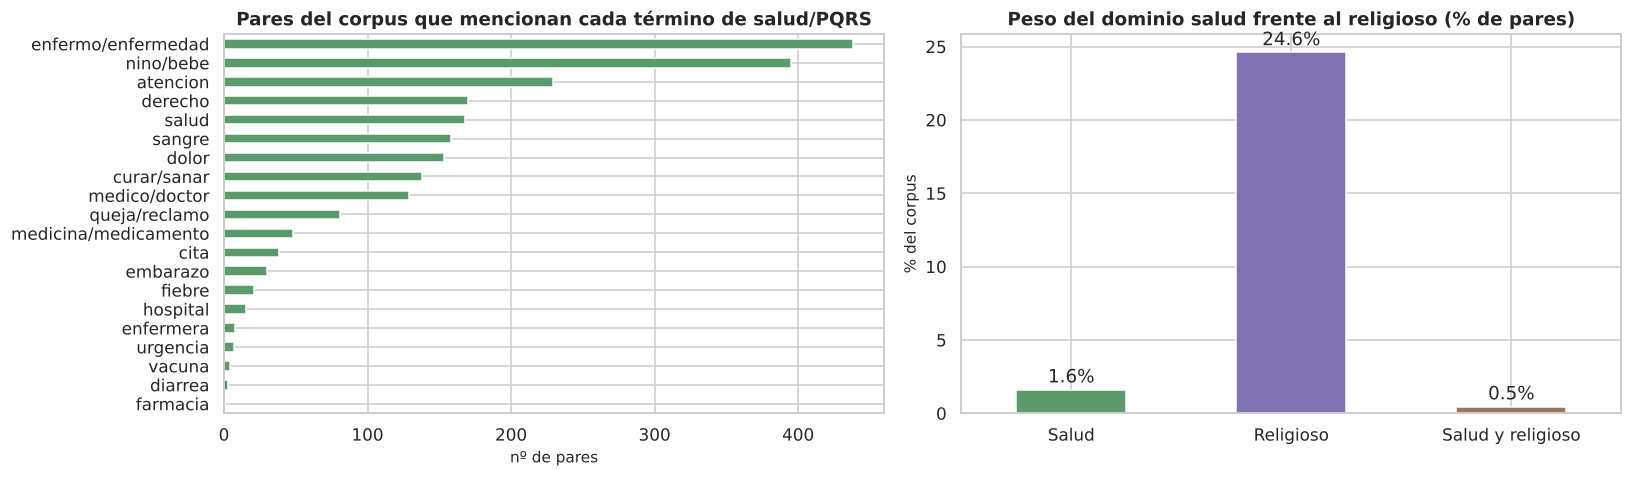

In [31]:
# Términos clave del dominio salud / PQRS (expresiones regulares sobre el español normalizado del corpus)
TERMINOS_SALUD = {
    "salud": r"\bsalud\b", "medico/doctor": r"\bmedic[oa]s?\b|\bdoctor(es|a)?\b", "hospital": r"\bhospital(es)?\b",
    "enfermo/enfermedad": r"\benferm\w*", "dolor": r"\bdolor(es)?\b", "medicina/medicamento": r"\bmedicin\w*|\bmedicament\w*|\bremedio\w*",
    "cita": r"\bcitas?\b", "fiebre": r"\bfiebre\b", "embarazo": r"\bembaraz\w*", "vacuna": r"\bvacun\w*",
    "sangre": r"\bsangre\b", "curar/sanar": r"\bcur(ar|o|a|aron)\b|\bsan(ar|o|ado)\b", "enfermera": r"\benfermer[oa]s?\b",
    "farmacia": r"\bfarmacia\b", "urgencia": r"\burgencias?\b", "diarrea": r"\bdiarrea\b", "nino/bebe": r"\bni\s?os?\b|\bbebes?\b",
    "queja/reclamo": r"\bquej\w*|\breclam\w*", "derecho": r"\bderechos?\b", "atencion": r"\batencion\b",
}
esp_n = df.esp.map(nkey)
cob = pd.DataFrame({
    "pares_que_lo_mencionan": {k: int(esp_n.str.contains(v).sum()) for k, v in TERMINOS_SALUD.items()},
})
cob["% del corpus"] = (100 * cob.pares_que_lo_mencionan / len(df)).round(3)
seg_health = {k: df.loc[esp_n.str.contains(v), "segmento"].value_counts(normalize=True).mul(100).round(0)
              for k, v in TERMINOS_SALUD.items()}
cob = cob.join(pd.DataFrame(seg_health).T.reindex(columns=seg_order).fillna(0).add_prefix("% en "))
cob = cob.sort_values("pares_que_lo_mencionan", ascending=False)
display(cob)

any_health = esp_n.str.contains("|".join(v for k, v in TERMINOS_SALUD.items() if k not in ("derecho", "atencion", "nino/bebe")))
relig = esp_n.str.contains(r"jehova|biblia|dios|jesus|cristo|biblic")
print(f"Pares con algún término de salud: {any_health.sum():,} ({100*any_health.mean():.1f}%)   |   "
      f"pares con términos religiosos: {relig.sum():,} ({100*relig.mean():.1f}%)")
print(f"De los pares 'de salud', cuántos también son religiosos: {100*(any_health & relig).sum()/any_health.sum():.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
cob.pares_que_lo_mencionan[::-1].plot.barh(ax=axes[0], color="#5b9b6b")
axes[0].set(title="Pares del corpus que mencionan cada término de salud/PQRS", xlabel="nº de pares")
dom = pd.Series({"Salud": any_health.mean(), "Religioso": relig.mean(),
                 "Salud y religioso": (any_health & relig).mean()}) * 100
dom.plot.bar(ax=axes[1], color=["#5b9b6b", "#8172b3", "#937860"], rot=0)
axes[1].set(title="Peso del dominio salud frente al religioso (% de pares)", ylabel="% del corpus")
for i, v in enumerate(dom): axes[1].text(i, v + .5, f"{v:.1f}%", ha="center")
plt.tight_layout(); plt.show()

### 7.2 Glosario de salud español → wayuunaiki extraído del corpus

Usamos las **entradas de diccionario** (pares de 1–2 palabras del segmento A) para buscar la traducción de términos que el bot necesita. Si un término no aparece, el bot **no puede** responderlo en wayuunaiki con datos de este corpus.

In [32]:
GLOSARIO_OBJETIVO = ["hola", "buenos dias", "gracias", "si", "no", "ayuda", "salud", "medico", "doctor", "enfermera",
                     "hospital", "enfermo", "enfermedad", "dolor", "fiebre", "diarrea", "tos", "medicina", "remedio",
                     "cita", "vacuna", "embarazada", "sangre", "cabeza", "estomago", "agua", "hijo", "madre", "abuela",
                     "curar", "queja", "reclamo", "derecho", "esperar", "pagar", "mañana", "hoy", "nombre", "documento"]
dic = df[(df.n_pal_esp <= 2) & (df.n_pal_way <= 3)].assign(k=lambda d: d.esp.map(nkey))
filas = []
for t in GLOSARIO_OBJETIVO:
    tr = dic.loc[dic.k == nkey(t), "way"].value_counts()
    filas.append({"termino_esp": t, "encontrado": len(tr) > 0, "n_variantes": len(tr),
                  "traducciones (frecuencia)": ", ".join(f"{w} ({c})" for w, c in tr.head(3).items()) if len(tr) else "—"})
glosario = pd.DataFrame(filas)
display(glosario)
print(f"Cobertura del glosario objetivo: {glosario.encontrado.sum()} de {len(glosario)} términos "
      f"({100*glosario.encontrado.mean():.0f}%).  Términos con >1 variante: {(glosario.n_variantes > 1).sum()}")
print("Sin traducción en el corpus:", ", ".join(glosario.loc[~glosario.encontrado, "termino_esp"]))
GLOS_CSV = Path("../data/raw/glosario_salud_esp_way.csv") if Path("../data/raw").exists() else Path("glosario_salud_esp_way.csv")
glosario.to_csv(GLOS_CSV, index=False)

,termino_esp,encontrado,n_variantes,traducciones (frecuencia)
0,hola,True,3,"jamaan (1), jamaya (1), Jamayaa (1)"
1,buenos dias,True,2,"wattachonya (19), watta'a maalü (1)"
2,gracias,True,3,"analu'ulu pümüin (2), anayaawatsüja'a (2), eleena ajaa (1)"
3,si,True,4,"aa (10), aa münakalü (1), jamüsa'a (1)"
4,no,True,9,"nnojo (9), nnojoo (6), nnojottaa (5)"
5,ayuda,True,1,akaaliijaa (1)
6,salud,False,0,—
7,medico,True,1,tottoolu (1)
8,doctor,False,0,—
9,enfermera,False,0,—


Cobertura del glosario objetivo: 26 de 39 términos (67%).  Términos con >1 variante: 15
Sin traducción en el corpus: salud, doctor, enfermera, hospital, dolor, tos, remedio, cita, vacuna, queja, reclamo, mañana, documento


**Lectura:**
- El corpus casi no habla de salud: los términos clave aparecen en una fracción mínima de los pares y, cuando aparecen, muchas veces es en contexto religioso (curaciones, "sangre", etc.).
- Varios términos esenciales para un bot de PQRS (**hospital, cita, vacuna, dolor, salud, queja, reclamo**…) **no tienen entrada de diccionario**; otros tienen **varias traducciones** distintas (variación dialectal u ortográfica, p. ej. *wuin / wüin* para "agua").
- **Implicación para el diseño:** el corpus sirve para **detectar** wayuunaiki y como base de un glosario, pero las respuestas del bot en wayuunaiki deben ser **mensajes cortos predefinidos, validados por hablantes nativos** (p. ej. con apoyo de autoridades tradicionales o intérpretes del hospital), y no traducción automática libre. El glosario resultante se guarda en `glosario_salud_esp_way.csv`.

### 7.3 Fuente complementaria: vocabulario de enfermedades del Portal UNICISO (F6)

Recurso de audios **"Enfermedades en wayuunaiki"** del [Portal UNICISO](https://www.portaluniciso.com/categoria-producto/wayuunaiki/), con colaboración wayuu de **Kelly Johana López Epieyu** y **Sharol Robles Epieyu**. Aporta términos de salud que el corpus no cubre (p. ej. *dolor*) y sirve para **validar de forma cruzada** el glosario: si una palabra aparece en ambas fuentes con el mismo significado, es más confiable.

La transcripción copiada del portal perdió el saltillo (`E iijaa` ↔ `e'iijaa` del corpus); se restaura donde el corpus confirma la forma y se marca como *hipótesis* donde no.

In [33]:
uniciso = pd.DataFrame([
    # termino_esp,          way (tal como aparece en el portal), way_normalizado (propuesta)
    ("dolor",               "Jali",       "jali"),
    ("dolor de cabeza",     "Jali ekii",  "jali ekii"),
    ("gripe",               "Shunui",     "shunui"),
    ("herida",              "Alio u",     "alio'u"),      # saltillo restaurado según el corpus (hipótesis)
    ("sanar una herida",    "Ashatta",    "ashatta"),
    ("tener gripa",         "Shunulii",   "shunulii"),
    ("tener frio",          "Akurulaa",   "akurulaa"),
    ("tener diarrea",       "E iijaa",    "e'iijaa"),     # saltillo restaurado: el corpus trae e'iijaa = diarrea
    ("tener fiebre",        "Oushuwaa",   "oushuwaa"),
    ("tener ampolla",       "Jolotoo",    "jolotoo"),
], columns=["termino_esp", "way_portal", "way"])
uniciso["fuente"] = "F6_UNICISO_audios"

# ¿La palabra wayuu aparece en el corpus? ¿con qué español se alinea allí?
way_norm = df.way.str.lower().str.replace(f"[{re.escape(APOS)}]", "'", regex=True)
def evidencia(w):
    m = way_norm.str.contains(rf"(?<![\w']){re.escape(w.split()[0])}(?![\w'])", regex=True)
    ejemplos = df.loc[m & (df.n_pal_esp <= 4), "esp"].value_counts().head(3).index.tolist()
    return pd.Series({"pares_en_corpus": int(m.sum()), "esp_alineado_en_corpus (pares cortos)": ", ".join(ejemplos) or "—"})
uniciso = uniciso.join(uniciso.way.apply(evidencia))
uniciso["estado"] = np.where(uniciso.pares_en_corpus > 0, "atestiguado en corpus", "solo UNICISO (validar)")
display(uniciso)

# Glosario combinado: corpus (7.2) + UNICISO
glo_corpus = glosario[glosario.encontrado].assign(
    way=lambda d: d["traducciones (frecuencia)"].str.split(" \(").str[0], fuente="F1_corpus")[["termino_esp", "way", "fuente"]]
glosario_final = (pd.concat([glo_corpus, uniciso[["termino_esp", "way", "fuente"]]], ignore_index=True)
                    .assign(validado_hablante_nativo=False))
glosario_final.to_csv(GLOS_CSV, index=False)
faltan = [t for t in glosario.loc[~glosario.encontrado, "termino_esp"] if t not in set(uniciso.termino_esp)]
print(f"Glosario combinado: {len(glosario_final)} entradas ({(glosario_final.fuente=='F1_corpus').sum()} del corpus + "
      f"{(glosario_final.fuente!='F1_corpus').sum()} de UNICISO) → glosario_salud_esp_way.csv")
print("Siguen sin traducción:", ", ".join(faltan))

,termino_esp,way_portal,way,fuente,pares_en_corpus,esp_alineado_en_corpus (pares cortos),estado
0,dolor,Jali,jali,F6_UNICISO_audios,1,—,atestiguado en corpus
1,dolor de cabeza,Jali ekii,jali ekii,F6_UNICISO_audios,1,—,atestiguado en corpus
2,gripe,Shunui,shunui,F6_UNICISO_audios,7,"pille un resfriado, me agarre una gripe, gripe",atestiguado en corpus
3,herida,Alio u,alio'u,F6_UNICISO_audios,1,herida,atestiguado en corpus
4,sanar una herida,Ashatta,ashatta,F6_UNICISO_audios,0,—,solo UNICISO (validar)
5,tener gripa,Shunulii,shunulii,F6_UNICISO_audios,0,—,solo UNICISO (validar)
6,tener frio,Akurulaa,akurulaa,F6_UNICISO_audios,1,tener frio,atestiguado en corpus
7,tener diarrea,E iijaa,e'iijaa,F6_UNICISO_audios,2,diarrea,atestiguado en corpus
8,tener fiebre,Oushuwaa,oushuwaa,F6_UNICISO_audios,4,"no te resfries, tengo fiebre alta, fiebre",atestiguado en corpus
9,tener ampolla,Jolotoo,jolotoo,F6_UNICISO_audios,1,ampolla,atestiguado en corpus


Glosario combinado: 36 entradas (26 del corpus + 10 de UNICISO) → glosario_salud_esp_way.csv
Siguen sin traducción: salud, doctor, enfermera, hospital, tos, remedio, cita, vacuna, queja, reclamo, mañana, documento


**Lectura de la validación cruzada:**
- **Coinciden en ambas fuentes:** *e'iijaa* (diarrea), *oushuwaa* (fiebre), *jolotoo* (ampolla), *akurulaa* (frío), *alio'u* (herida), *shunui* (resfriado/gripe). Son los términos más confiables del glosario.
- ***oushuwaa* vs *tuttaa*:** el corpus traduce "fiebre" con las dos formas; UNICISO usa *oushuwaa* para "tener fiebre". Hay que preguntar a hablantes cuál es la más usada en La Guajira colombiana.
- ***jali* (dolor):** aparece una sola vez en el corpus y dentro de una oración larga, sin poder confirmar el significado; ***ashatta*** y ***shunulii*** no aparecen. Estos tres vienen solo de UNICISO y quedan como *pendientes de validar*.
- El saltillo perdido al copiar del portal (`E iijaa`) es el mismo problema de normalización de la sección 5.4: hay que tomar las formas escritas de los **audios** o con apoyo de las colaboradoras.

## 8. Dataset PQRS sintético (variable objetivo del clasificador)

### 8.1 Generación
Diseño del dataset (fuente F2):

| Campo | Descripción |
|---|---|
| `texto` | mensaje del usuario tal como llegaría por WhatsApp |
| `tipo_pqrs` | **etiqueta principal**: `Peticion`, `Queja`, `Reclamo`, `Sugerencia`, `Otro` (saludos, agradecimientos, fuera de dominio, sin contenido) |
| `intencion` | intención fina (16 + `sin_contenido`): p. ej. `solicitar_cita`, `medicamento_no_entregado`, `mal_trato`… |
| `registro` | `formal` (con tildes y fórmulas de cortesía), `coloquial` (abreviaturas, emojis), `simplificado` (baja alfabetización: errores ortográficos, frases telegráficas, mayúsculas sostenidas) |
| `wayuunaiki` | `True` si el mensaje mezcla palabras en wayuunaiki **tomadas del corpus** (sección 7.2) |
| `plantilla_id` | plantilla de origen (se usa para evitar fuga al dividir en train/test) |
| `fuente` | `sintetico_plantillas`, `sintetico_ruido` (vacíos / emojis), `sintetico_audio_transcrito` |

Criterios de etiquetado (basados en las definiciones de PQRS): **Petición** = solicitud de un servicio, documento o información; **Queja** = inconformidad con la *conducta* del personal o las condiciones de la atención; **Reclamo** = inconformidad por la *no prestación o prestación deficiente* de un servicio (medicamento no entregado, cita incumplida, cobro indebido, servicio negado); **Sugerencia** = propuesta de mejora.

In [34]:
# ═══════════════════════════════════════════════════════════════════════════
# Generador del dataset SINTÉTICO de PQRS en salud (mensajes tipo WhatsApp)
# Reproducible (semilla fija). Cada fila = 1 mensaje de un usuario.
#   tipo_pqrs : Peticion | Queja | Reclamo | Sugerencia | Otro   (objetivo principal)
#   intencion : intención fina (subclase) que usará el bot para responder
#   registro  : formal | coloquial | simplificado (baja alfabetización)
#   wayuunaiki: el mensaje incluye palabras en wayuunaiki (code-switching)
# Los problemas de calidad típicos de WhatsApp (vacíos, solo emojis, reenvíos,
# audios transcritos larguísimos, errores ortográficos) se INYECTAN a propósito
# en proporciones bajas para que el EDA y el preprocesamiento los contemplen.
# ═══════════════════════════════════════════════════════════════════════════
import random

RNG_SEED = 42
rng = random.Random(RNG_SEED)

SLOTS = {
    "servicio": ["medicina general", "odontologia", "pediatria", "control prenatal", "vacunacion",
                 "laboratorio", "ginecologia", "medicina interna", "urgencias", "psicologia", "nutricion"],
    "entidad": ["la EPS", "el hospital", "el puesto de salud", "la IPS", "el centro de salud", "la clinica"],
    "lugar": ["Riohacha", "Uribia", "Maicao", "Manaure", "Albania", "Dibulla", "Nazareth", "la Alta Guajira",
              "la rancheria", "Fonseca"],
    "medicamento": ["acetaminofen", "losartan", "metformina", "insulina", "amoxicilina", "ibuprofeno",
                    "sales de rehidratacion", "acido folico", "salbutamol", "enalapril"],
    "duracion": ["una semana", "15 dias", "un mes", "dos semanas", "tres dias"],
    "tiempo": ["hace una semana", "hace 15 dias", "hace un mes", "desde ayer", "hace tres meses", "desde el lunes",
               "hace dos semanas"],
    "persona": ["mi hijo", "mi hija", "mi mama", "mi papa", "mi esposa", "mi abuela", "mi bebe", "mi esposo"],
    "documento": ["la historia clinica", "un certificado medico", "la incapacidad", "los resultados de laboratorio",
                  "la formula medica", "el carnet de vacunas"],
}

# Plantillas por (tipo, intención). Se escriben en registro "base"; luego se transforman por registro.
T = {
 ("Peticion", "solicitar_cita"): [
    "necesito una cita de {servicio} para {persona}",
    "quiero pedir cita con {servicio} en {lugar}",
    "como hago para sacar una cita de {servicio}",
    "me pueden dar una cita de {servicio} lo mas pronto posible",
    "solicito asignacion de cita de {servicio} para {persona}"],
 ("Peticion", "solicitar_autorizacion"): [
    "necesito la autorizacion para {servicio} que me mando el medico",
    "como tramito la autorizacion de {medicamento} en {entidad}",
    "quiero que me autoricen el examen de {servicio}",
    "solicito autorizacion de la orden de {servicio} para {persona}"],
 ("Peticion", "solicitar_documento"): [
    "necesito {documento} de {persona}",
    "como pido {documento} en {entidad}",
    "solicito copia de {documento}",
    "me pueden enviar {documento} por aqui"],
 ("Peticion", "solicitar_interprete"): [
    "necesito un interprete de wayuunaiki para la cita de {persona}",
    "{persona} no habla bien espanol, hay alguien que traduzca en {entidad}",
    "pido que en la cita de {servicio} haya traductor wayuu"],
 ("Peticion", "consultar_estado"): [
    "quiero saber como va mi solicitud que mande {tiempo}",
    "en que va el tramite que radique {tiempo}",
    "me dieron un numero de radicado y no me han respondido, en que va"],
 ("Queja", "mal_trato"): [
    "en {entidad} de {lugar} me atendieron muy mal, la persona de la ventanilla me grito",
    "el medico de {servicio} fue grosero con {persona}",
    "me trataron mal en {entidad} por no hablar bien espanol",
    "la enfermera no nos quiso atender y nos hablo feo"],
 ("Queja", "demora_atencion"): [
    "llevo horas esperando en {entidad} de {lugar} y nadie me atiende",
    "{persona} esta en urgencias desde ayer y todavia no hay medico que atienda",
    "la fila en {entidad} es demasiado larga, esperamos todo el dia",
    "llegamos temprano de {lugar} y nos atendieron en la noche"],
 ("Queja", "infraestructura"): [
    "el puesto de salud de {lugar} no tiene agua ni luz",
    "en {entidad} no hay sillas y la gente espera parada al sol",
    "los banos de {entidad} estan danados y sucios",
    "no hay ambulancia en {lugar} para traer a los enfermos"],
 ("Reclamo", "medicamento_no_entregado"): [
    "no me han entregado el {medicamento} que me formularon {tiempo}",
    "fui a la farmacia y no habia {medicamento} para {persona}",
    "me dieron la formula de {medicamento} pero la farmacia dice que no hay",
    "llevo {duracion} sin {medicamento} y lo necesito para {persona}"],
 ("Reclamo", "cita_incumplida"): [
    "me cancelaron la cita de {servicio} y no me la reprogramaron",
    "viajamos desde {lugar} para la cita y el medico no llego",
    "tenia cita de {servicio} {tiempo} y nunca me llamaron",
    "me cambiaron la cita de {servicio} sin avisar"],
 ("Reclamo", "cobro_indebido"): [
    "me cobraron por {servicio} y eso lo cubre {entidad}",
    "me hicieron pagar una cuota que no me corresponde",
    "en {entidad} me cobraron el {medicamento} que es gratis",
    "me exigieron pagar para atender a {persona} en urgencias"],
 ("Reclamo", "servicio_negado"): [
    "me negaron la autorizacion de {servicio} sin explicacion",
    "no quisieron atender a {persona} porque dicen que no esta afiliado",
    "{entidad} se niega a dar la orden de {servicio}",
    "me dijeron que no me pueden atender en {lugar}"],
 ("Sugerencia", "mejorar_atencion"): [
    "seria bueno que en {entidad} hubiera mas personal en las mananas",
    "sugiero que den turnos por mensaje para no hacer fila",
    "deberian poner un toldo para la gente que espera afuera en {entidad}",
    "recomiendo que el personal explique con palabras sencillas"],
 ("Sugerencia", "enfoque_intercultural"): [
    "deberian tener personal que hable wayuunaiki en {entidad}",
    "seria bueno que hagan brigadas de salud en {lugar}",
    "sugiero que los avisos esten en wayuunaiki y en espanol",
    "propongo que respeten la medicina tradicional wayuu en la atencion"],
 ("Otro", "saludo"): ["hola", "buenos dias", "buenas tardes", "hola buenas", "buenas noches, una pregunta"],
 ("Otro", "agradecimiento"): ["gracias", "muchas gracias por la ayuda", "ok gracias", "listo, gracias", "muy amable"],
 ("Otro", "fuera_de_dominio"): ["a que hora juega el junior", "quien gano la loteria", "me vende una recarga",
                                "necesito trabajo", "cuanto cuesta el pasaje a Maicao"],
}

# Distribución objetivo (desbalance REALISTA y deliberado: las sugerencias son las menos frecuentes)
TIPO_P = {"Peticion": .32, "Reclamo": .27, "Queja": .21, "Otro": .13, "Sugerencia": .07}
REG_P = {"formal": .20, "coloquial": .50, "simplificado": .30}
N_MENSAJES = 3000

# Palabras en wayuunaiki ATESTIGUADAS en el corpus paralelo (sección 7.1); requieren validación de hablante nativo
WAY_LEX = {"hola": "jamaya", "buenos dias": "wattachonya", "gracias": "anayaawatsüja'a",
           "enfermo": "ayuulii", "medico": "tottoolu", "fiebre": "tuttaa", "si": "aa", "no": "nnojo"}

FORMAL_PRE = ["Buenos días, ", "Cordial saludo. ", "Señores, ", "Por medio de la presente, "]
FORMAL_POS = [". Agradezco su atención.", ". Quedo atento.", ". Muchas gracias.", "."]
COLOQ_PRE = ["buenas ", "hola ", "", "", "porfa ", "oiga "]
COLOQ_POS = ["", "", " porfa", " 🙏", " ayuda", "!!", " ??"]
TILDES = {"medico": "médico", "clinica": "clínica", "autorizacion": "autorización", "rancheria": "ranchería",
          "solicitud": "solicitud", "espanol": "español", "bebe": "bebé", "mama": "mamá", "papa": "papá",
          "dias": "días", "danados": "dañados", "mananas": "mañanas", "historia clinica": "historia clínica",
          "odontologia": "odontología", "pediatria": "pediatría", "vacunacion": "vacunación",
          "ginecologia": "ginecología", "psicologia": "psicología", "nutricion": "nutrición",
          "acetaminofen": "acetaminofén", "losartan": "losartán", "acido": "ácido", "interprete": "intérprete",
          "asignacion": "asignación", "tramite": "trámite", "atencion": "atención", "explicacion": "explicación",
          "afiliado": "afiliado", "examenes": "exámenes", "rehidratacion": "rehidratación", "numero": "número"}
# Errores frecuentes en escritura con baja alfabetización / teclado del celular
SIMPLE_SUBS = [("ci", "si"), ("ce", "se"), ("qu", "k"), ("que", "q"), ("por que", "xq"), ("para", "pa"),
               ("ll", "y"), ("v", "b"), ("h", ""), ("medicamento", "medisina"), ("cita", "sita"),
               ("necesito", "nesesito"), ("hace", "ase")]
ABREV = [("que", "q"), ("por favor", "xfa"), ("para", "pa"), ("tambien", "tb"), ("porque", "xq")]

def render(tpl):
    return re.sub(r"\{(\w+)\}", lambda m: rng.choice(SLOTS[m.group(1)]), tpl)

def a_formal(t, tipo=None):
    for k, v in sorted(TILDES.items(), key=lambda kv: -len(kv[0])):
        t = re.sub(rf"\b{k}\b", v, t)
    if tipo == "Otro":                                 # saludos/agradecimientos: solo mayúscula inicial
        return t[0].upper() + t[1:] + "."
    t = rng.choice(FORMAL_PRE) + t
    t = t[0].upper() + t[1:]
    if t.lower().startswith(("como", "en que", "quiero saber")):
        t = "¿" + t + "?"
    return t + ("" if t.endswith("?") else rng.choice(FORMAL_POS))

def a_coloquial(t):
    for k, v in ABREV:
        if rng.random() < .35:
            t = re.sub(rf"\b{k}\b", v, t)
    return rng.choice(COLOQ_PRE) + t + rng.choice(COLOQ_POS)

def a_simplificado(t):
    # estilo telegráfico: se omiten algunos artículos/preposiciones
    t = " ".join(w for w in t.split() if not (w in {"la", "el", "los", "las", "de", "un", "una"} and rng.random() < .4))
    for a, b in SIMPLE_SUBS:
        if rng.random() < .30:
            t = t.replace(a, b)
    return t.upper() if rng.random() < .15 else t      # algunos escriben todo en mayúscula

def add_wayuunaiki(t):
    # code-switching: saludo y/o un término de salud en wayuunaiki
    if rng.random() < .6:
        t = rng.choice([WAY_LEX["hola"], WAY_LEX["buenos dias"]]) + " " + t
    for es in ("enfermo", "medico", "fiebre"):
        t = re.sub(rf"\b{es}\b", WAY_LEX[es], t)
    if rng.random() < .4:
        t += " " + rng.choice(["ayuulii", "tuttaa"])   # 'enfermo', 'fiebre'
    return t

def generar(n=N_MENSAJES):
    rows = []
    tipos, pt = zip(*TIPO_P.items())
    regs, pr = zip(*REG_P.items())
    for i in range(n):
        tipo = rng.choices(tipos, pt)[0]
        intencion = rng.choice([k[1] for k in T if k[0] == tipo])
        reg = rng.choices(regs, pr)[0]
        j = rng.randrange(len(T[(tipo, intencion)]))
        txt = render(T[(tipo, intencion)][j])
        # 8 % de quejas/reclamos con una segunda queja/reclamo en el mismo mensaje (ambigüedad de etiqueta)
        if tipo in ("Queja", "Reclamo") and rng.random() < .08:
            otro = rng.choice([k for k in T if k[0] in ("Queja", "Reclamo") and k[1] != intencion])
            txt += " y ademas " + render(rng.choice(T[otro]))
        txt = a_formal(txt, tipo) if reg == "formal" else (a_coloquial(txt) if reg == "coloquial" else a_simplificado(txt))
        way = rng.random() < (.20 if reg == "simplificado" else .06)
        if way:
            txt = add_wayuunaiki(txt)
        rows.append(dict(id_msg=f"M{i:05d}", texto=txt, tipo_pqrs=tipo, intencion=intencion,
                         registro=reg, wayuunaiki=way, plantilla_id=f"{intencion}_{j}",
                         fuente="sintetico_plantillas"))
    d = pd.DataFrame(rows)

    # ── Ruido realista de WhatsApp (proporciones bajas, documentadas) ────────────
    # (a) reenvíos: el mismo usuario manda dos veces el mismo mensaje
    reenv = d.sample(frac=.04, random_state=RNG_SEED).assign(id_msg=lambda x: x.id_msg + "_r")
    # (b) mensajes vacíos o solo emojis / stickers (sin texto útil)
    vac = pd.DataFrame(dict(id_msg=[f"V{i:04d}" for i in range(30)],
                            texto=[rng.choice(["", " ", "👍", "🙏🙏", "😡", "...", "?"]) for _ in range(30)],
                            tipo_pqrs="Otro", intencion="sin_contenido", registro="coloquial",
                            wayuunaiki=False, plantilla_id="ruido", fuente="sintetico_ruido"))
    # (c) audios transcritos: mensajes muy largos que concatenan varias frases
    largos = []
    for i in range(15):
        k = rng.choice([k for k in T if k[0] in ("Queja", "Reclamo")])
        j = rng.randrange(len(T[k]))
        frases = [render(T[k][j])] + [render(rng.choice(T[k])) for _ in range(rng.randint(7, 13))]
        largos.append(dict(id_msg=f"A{i:04d}", texto=" eee pues ".join(frases), tipo_pqrs=k[0], intencion=k[1],
                           registro="coloquial", wayuunaiki=False, plantilla_id=f"{k[1]}_{j}",
                           fuente="sintetico_audio_transcrito"))
    d = pd.concat([d, reenv, vac, pd.DataFrame(largos)], ignore_index=True)
    return d.sample(frac=1, random_state=RNG_SEED).reset_index(drop=True)   # barajar

pqrs = generar()
OUT_CSV = Path("../data/raw/pqrs_salud_sintetico.csv") if Path("../data/raw").exists() else Path("pqrs_salud_sintetico.csv")
pqrs.to_csv(OUT_CSV, index=False)
print(f"Dataset PQRS sintético: {len(pqrs):,} mensajes → {OUT_CSV}")
display(pqrs.sample(12, random_state=1)[["texto", "tipo_pqrs", "intencion", "registro", "wayuunaiki"]])

Dataset PQRS sintético: 3,165 mensajes → ../data/raw/pqrs_salud_sintetico.csv


,texto,tipo_pqrs,intencion,registro,wayuunaiki
756,sugiero que den turnos por mensaje para no hacer fila!!,Sugerencia,mejorar_atencion,coloquial,False
1089,en puesto de salud me cobraron el ibuprofeno q es gratis,Reclamo,cobro_indebido,simplificado,False
2312,"Buenos días, me cobraron por medicina interna y eso lo cubre el hospital. Agradezco su...",Reclamo,cobro_indebido,formal,False
499,"Buenos días, pido que en la cita de vacunación haya traductor wayuu. Muchas gracias.",Peticion,solicitar_interprete,formal,False
3004,me dieron formula losartan pero la farmacia dice ke no ay y ademas me dijeron ke no me...,Reclamo,medicamento_no_entregado,simplificado,False
2952,oiga necesito el carnet de vacunas de mi esposa porfa,Peticion,solicitar_documento,coloquial,False
1159,me cobraron por urgencias y eso lo cubre la EPS,Reclamo,cobro_indebido,coloquial,False
1145,en ke va tramite ke radike ace dos semanas,Peticion,consultar_estado,simplificado,False
2369,Cordial saludo. quiero saber como va mi solicitud que mande hace tres meses. Muchas gr...,Peticion,consultar_estado,formal,False
713,"mi esposo no habla bien espanol, hay alguien que traduzca en el puesto de salud",Peticion,solicitar_interprete,simplificado,False


### 8.2 Carga y descripción del dataset

In [35]:
pqrs = pd.read_csv(OUT_CSV, keep_default_na=False, dtype={"texto": str})
print(f"Forma: {pqrs.shape}")
pqrs.info()
display(pqrs.head(8))
display(pqrs.describe(include="all").T[["count", "unique", "top", "freq"]])

Forma: (3165, 8)
<class 'pandas.DataFrame'>
RangeIndex: 3165 entries, 0 to 3164
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id_msg        3165 non-null   str  
 1   texto         3165 non-null   str  
 2   tipo_pqrs     3165 non-null   str  
 3   intencion     3165 non-null   str  
 4   registro      3165 non-null   str  
 5   wayuunaiki    3165 non-null   bool 
 6   plantilla_id  3165 non-null   str  
 7   fuente        3165 non-null   str  
dtypes: bool(1), str(7)
memory usage: 176.3 KB


,id_msg,texto,tipo_pqrs,intencion,registro,wayuunaiki,plantilla_id,fuente
0,M02618,oiga pido q en la cita de vacunacion haya traductor wayuu 🙏,Peticion,solicitar_interprete,coloquial,False,solicitar_interprete_2,sintetico_plantillas
1,M00346,"Por medio de la presente, pido que en la cita de psicología haya traductor wayuu. Much...",Peticion,solicitar_interprete,formal,False,solicitar_interprete_2,sintetico_plantillas
2,M00170,PIDO Q EN CITA DE MEDICINA GENERAL HAYA TRADUCTOR WAYUU,Peticion,solicitar_interprete,simplificado,False,solicitar_interprete_2,sintetico_plantillas
3,M00354,oiga mi mama esta en urgencias desde ayer y todavia no hay medico q atienda,Queja,demora_atencion,coloquial,False,demora_atencion_1,sintetico_plantillas
4,M01558,wattachonya mi mama esta en urgensias desde ayer y todavia no hay tottoolu ke atienda,Queja,demora_atencion,simplificado,True,demora_atencion_1,sintetico_plantillas
5,M00761,COMO PIDO CARNET DE VACUNAS EN LA EPS,Peticion,solicitar_documento,simplificado,False,solicitar_documento_1,sintetico_plantillas
6,M00408,ok gracias ??,Otro,agradecimiento,coloquial,False,agradecimiento_2,sintetico_plantillas
7,M02720,me hicieron pagar cuota q no me corresponde,Reclamo,cobro_indebido,simplificado,False,cobro_indebido_1,sintetico_plantillas


,count,unique,top,freq
id_msg,3165,3165,M02618,1
texto,3165,2744,Necesito trabajo.,11
tipo_pqrs,3165,5,Peticion,989
intencion,3165,18,demora_atencion,256
registro,3165,3,coloquial,1640
wayuunaiki,3165,2,False,2846
plantilla_id,3165,71,solicitar_interprete_2,78
fuente,3165,3,sintetico_plantillas,3120


### 8.3 Estadísticas descriptivas

In [36]:
pqrs["n_pal"] = pqrs.texto.map(lambda s: len(tok(s)))
pqrs["n_car"] = pqrs.texto.str.len()
CLASES = ["Peticion", "Queja", "Reclamo", "Sugerencia", "Otro"]

print("Longitud de los mensajes (palabras):")
display(pqrs.n_pal.describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(1).to_frame().T)
print("Longitud por clase:")
display(pqrs.groupby("tipo_pqrs").n_pal.describe().reindex(CLASES).round(1))

dist = pd.DataFrame({"mensajes": pqrs.tipo_pqrs.value_counts().reindex(CLASES)})
dist["%"] = (100 * dist.mensajes / len(pqrs)).round(1)
print("Distribución de la variable objetivo (tipo_pqrs):"); display(dist)
print("Registro × clase (% por fila):")
display(pd.crosstab(pqrs.tipo_pqrs, pqrs.registro, normalize="index").reindex(CLASES).mul(100).round(1))
print(f"Mensajes con wayuunaiki: {pqrs.wayuunaiki.sum():,} ({100*pqrs.wayuunaiki.mean():.1f}%)  "
      f"→ en registro simplificado: {100*pqrs[pqrs.registro=='simplificado'].wayuunaiki.mean():.1f}%")

voc_pqrs = Counter(t for s in pqrs.texto for t in tok(s))
print(f"Vocabulario: {len(voc_pqrs):,} tipos, {sum(voc_pqrs.values()):,} tokens")

Longitud de los mensajes (palabras):


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
n_pal,3165.0,11.8,10.1,0.0,2.0,9.0,11.0,14.0,19.0,28.0,193.0


Longitud por clase:


,count,mean,std,min,25%,50%,75%,max
tipo_pqrs,,,,,,,,
Peticion,989.0,11.1,3.0,4.0,9.0,11.0,13.0,22.0
Queja,727.0,15.1,13.2,6.0,11.0,13.0,16.0,179.0
Reclamo,853.0,13.9,12.9,6.0,10.0,12.0,14.0,193.0
Sugerencia,191.0,11.6,2.6,7.0,10.0,11.0,13.5,20.0
Otro,405.0,3.1,1.8,0.0,2.0,3.0,4.0,8.0


Distribución de la variable objetivo (tipo_pqrs):


,mensajes,%
tipo_pqrs,,
Peticion,989,31.2
Queja,727,23.0
Reclamo,853,27.0
Sugerencia,191,6.0
Otro,405,12.8


Registro × clase (% por fila):


registro,coloquial,formal,simplificado
tipo_pqrs,,,
Peticion,49.7,20.1,30.1
Queja,52.4,18.3,29.3
Reclamo,52.9,18.5,28.6
Sugerencia,53.4,16.2,30.4
Otro,52.8,19.0,28.1


Mensajes con wayuunaiki: 319 (10.1%)  → en registro simplificado: 21.9%
Vocabulario: 416 tipos, 37,307 tokens


### 8.4 Visualizaciones

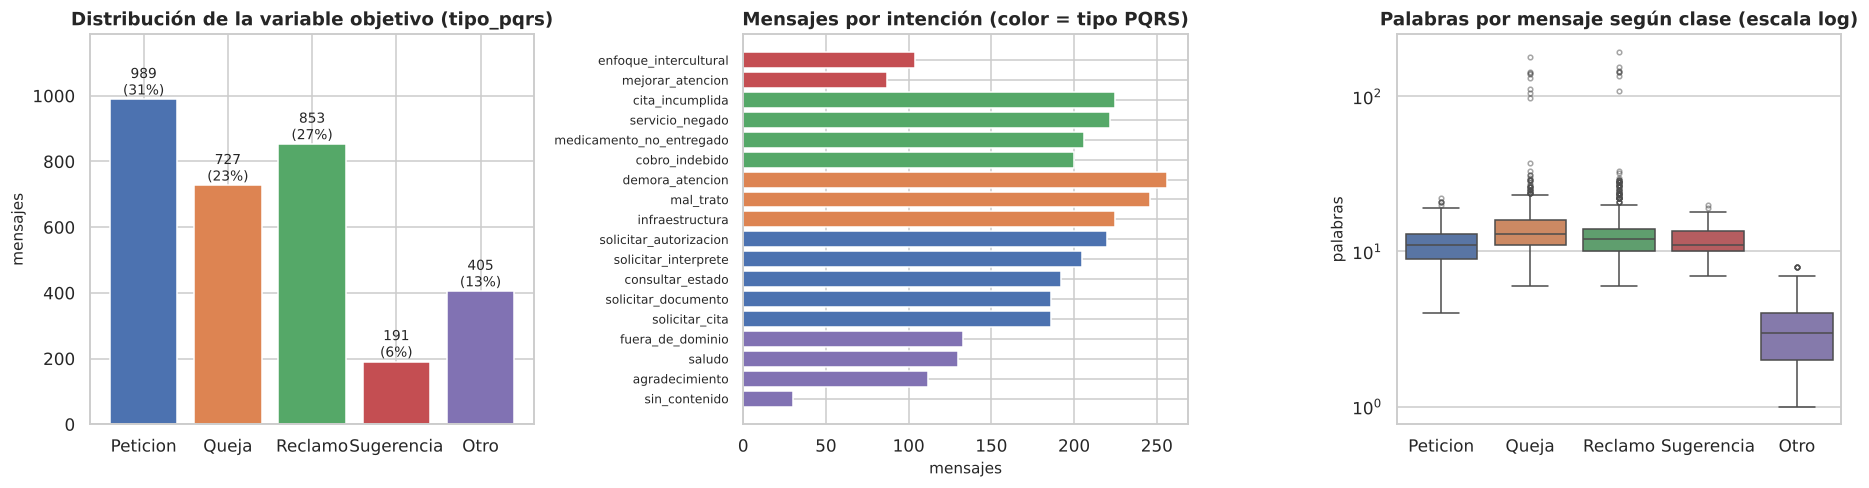

In [37]:
pal = dict(zip(CLASES, sns.color_palette("deep")[:5]))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

# (a) Distribución de clases (desbalance)
vc = pqrs.tipo_pqrs.value_counts().reindex(CLASES)
axes[0].bar(vc.index, vc.values, color=[pal[c] for c in vc.index])
for i, v in enumerate(vc.values): axes[0].text(i, v + 15, f"{v}\n({100*v/len(pqrs):.0f}%)", ha="center", fontsize=9)
axes[0].set(title="Distribución de la variable objetivo (tipo_pqrs)", ylabel="mensajes"); axes[0].set_ylim(0, vc.max() * 1.2)

# (b) Intenciones finas
iv = pqrs.groupby(["tipo_pqrs", "intencion"]).size().reset_index(name="n").sort_values(["tipo_pqrs", "n"])
axes[1].barh(iv.intencion, iv.n, color=[pal[c] for c in iv.tipo_pqrs])
axes[1].set(title="Mensajes por intención (color = tipo PQRS)", xlabel="mensajes"); axes[1].tick_params(axis="y", labelsize=8)

# (c) Longitud por clase
sns.boxplot(data=pqrs, x="tipo_pqrs", y=pqrs.n_pal.clip(lower=1), order=CLASES, ax=axes[2], palette=pal,
            flierprops=dict(markersize=3, alpha=.5))
axes[2].set_yscale("log"); axes[2].set(title="Palabras por mensaje según clase (escala log)", xlabel="", ylabel="palabras")
plt.tight_layout(); plt.show()

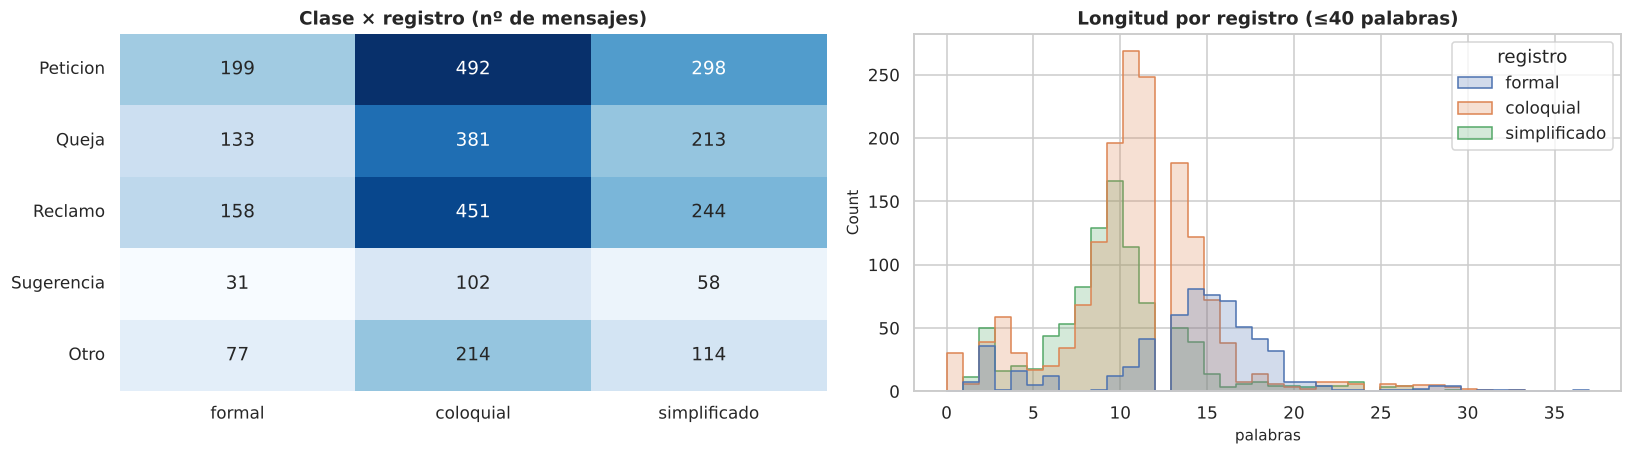

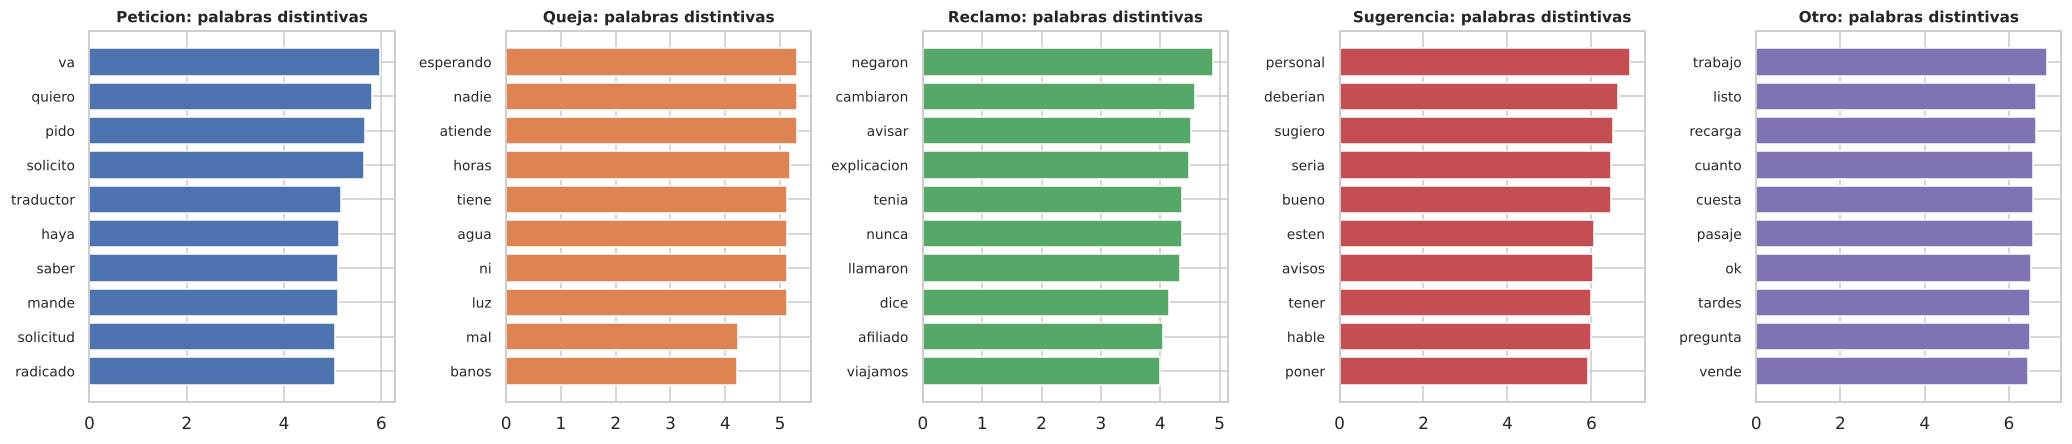

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
ct = pd.crosstab(pqrs.tipo_pqrs, pqrs.registro).reindex(CLASES)[["formal", "coloquial", "simplificado"]]
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set(title="Clase × registro (nº de mensajes)", xlabel="", ylabel="")
sns.histplot(data=pqrs[pqrs.n_pal <= 40], x="n_pal", hue="registro", bins=40, element="step", ax=axes[1],
             hue_order=["formal", "coloquial", "simplificado"])
axes[1].set(title="Longitud por registro (≤40 palabras)", xlabel="palabras")
plt.tight_layout(); plt.show()

# Palabras más características de cada clase (log-odds frente al resto, con suavizado)
STOP = SP_STOP | {"me", "mi", "y", "a", "no", "q", "pa", "hola", "buenas", "porfa"}
cnt_cls = {c: Counter(t for s in pqrs.loc[pqrs.tipo_pqrs == c, "texto"] for t in tok(s) if t not in STOP) for c in CLASES}
tot = Counter(); [tot.update(v) for v in cnt_cls.values()]
fig, axes = plt.subplots(1, 5, figsize=(19, 4.2))
for ax, c in zip(axes, CLASES):
    a, n_a = cnt_cls[c], sum(cnt_cls[c].values())
    n_b = sum(tot.values()) - n_a
    lo = {w: np.log((a[w] + 1) / (n_a + 1)) - np.log((tot[w] - a[w] + 1) / (n_b + 1)) for w in a if a[w] >= 5}
    s = pd.Series(lo).nlargest(10)[::-1]
    ax.barh(s.index, s.values, color=pal[c]); ax.set_title(f"{c}: palabras distintivas", fontsize=10)
    ax.tick_params(axis="y", labelsize=9)
plt.tight_layout(); plt.show()

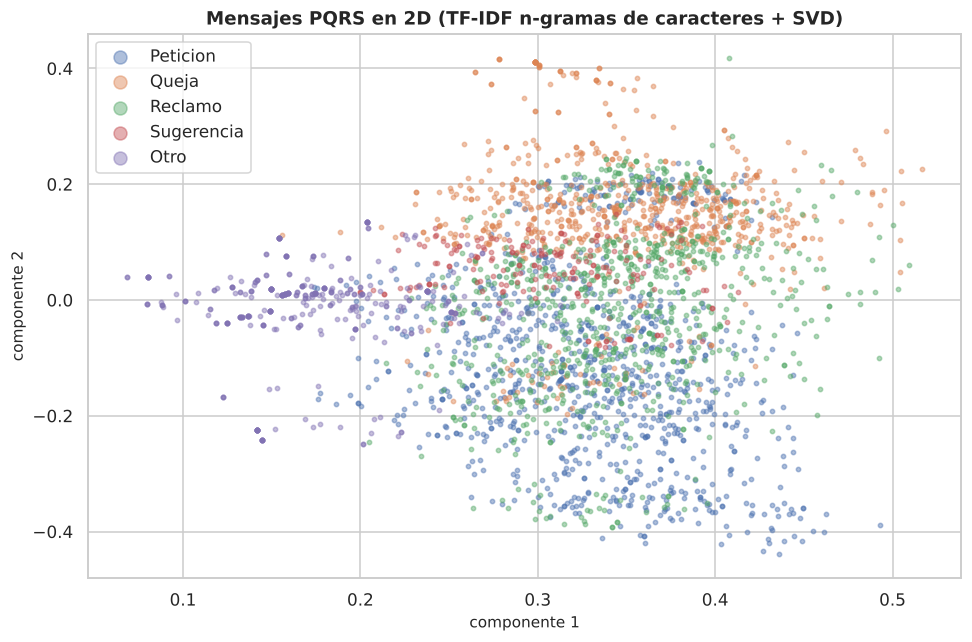

In [39]:
# Proyección 2D (TF-IDF de caracteres → SVD): ¿qué tan separables son las clases a simple vista?
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
txt_ok = pqrs[pqrs.n_pal > 0]
Xp = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=3, sublinear_tf=True).fit_transform(txt_ok.texto.str.lower())
Z = TruncatedSVD(2, random_state=0).fit_transform(Xp)
fig, ax = plt.subplots(figsize=(9, 6))
for c in CLASES:
    m = (txt_ok.tipo_pqrs == c).values
    ax.scatter(Z[m, 0], Z[m, 1], s=8, alpha=.45, label=c, color=pal[c])
ax.set(title="Mensajes PQRS en 2D (TF-IDF n-gramas de caracteres + SVD)", xlabel="componente 1", ylabel="componente 2")
ax.legend(markerscale=3); plt.tight_layout(); plt.show()

### 8.5 Problemas de calidad de datos del dataset PQRS
#### 8.5.1 Nulos, vacíos y mensajes sin contenido

In [40]:
EMOJI_RE = re.compile(r"[\U0001F300-\U0001FAFF☀-➿]")
q = pd.Series({
    "NaN": int(pqrs.texto.isna().sum()),
    "cadena vacía / solo espacios": int((pqrs.texto.str.strip() == "").sum()),
    "sin ninguna palabra (solo emojis/puntuación)": int(((pqrs.n_pal == 0) & (pqrs.texto.str.strip() != "")).sum()),
    "contiene emojis": int(pqrs.texto.str.contains(EMOJI_RE).sum()),
    "todo en MAYÚSCULAS (≥3 letras)": int(pqrs.texto.map(lambda s: sum(ch.isalpha() for ch in s) >= 3 and s.upper() == s).sum()),
    "espacios dobles / al inicio o fin": int((pqrs.texto.str.contains(r"\s{2,}") | (pqrs.texto != pqrs.texto.str.strip())).sum()),
}, name="mensajes").to_frame()
q["%"] = (100 * q.mensajes / len(pqrs)).round(2)
display(q)
print("Ejemplos sin contenido:", pqrs.loc[pqrs.n_pal == 0, "texto"].map(repr).unique()[:8])

,mensajes,%
NaN,0,0.00
cadena vacía / solo espacios,7,0.22
sin ninguna palabra (solo emojis/puntuación),23,0.73
contiene emojis,266,8.40
todo en MAYÚSCULAS (≥3 letras),115,3.63
espacios dobles / al inicio o fin,5,0.16


Ejemplos sin contenido: <StringArray>
[''👍'', ''...'', ''🙏🙏'', ''?'', ''😡'', '' '', '''']
Length: 7, dtype: str


#### 8.5.2 Duplicados y reenvíos

In [41]:
def nkey_msg(s):   # normaliza ortografía típica para detectar casi-duplicados
    s = nkey(s)
    for a, b in [("k", "qu"), ("x", "por"), ("sita", "cita"), ("pa ", "para ")]:
        s = s.replace(a, b)
    return re.sub(r"\b(hola|buenas|porfa|oiga|ayuda|q)\b", "", s).strip()

cont = pqrs[pqrs.n_pal > 0]
d_exact = cont.texto.duplicated().sum()
d_norm = cont.texto.map(nkey_msg).duplicated().sum()
d_lab = cont.duplicated(["texto", "tipo_pqrs"]).sum()
print(f"Duplicados exactos de texto: {d_exact:,} ({100*d_exact/len(cont):.1f}%)")
print(f"Casi-duplicados tras normalizar: {d_norm:,} ({100*d_norm/len(cont):.1f}%)")
print(f"Reenvíos marcados (id con sufijo _r): {pqrs.id_msg.str.endswith('_r').sum():,}")
top_dup = cont.texto.value_counts().head(10)
display(top_dup.to_frame("veces"))

# Mismo texto (normalizado) con etiquetas distintas → ambigüedad / ruido de etiqueta
g = cont.assign(k=cont.texto.map(nkey_msg)).groupby("k").tipo_pqrs.nunique()
print(f"Textos normalizados con >1 tipo_pqrs distinto (etiquetas contradictorias): {(g > 1).sum()}")
mixtos = cont[cont.texto.str.contains(r"\bademas\b", case=False) & cont.tipo_pqrs.isin(["Queja", "Reclamo"])]
print(f"Quejas/reclamos que combinan dos motivos en un mismo mensaje: {len(mixtos)} "
      f"({100*len(mixtos)/cont.tipo_pqrs.isin(['Queja','Reclamo']).sum():.1f}% de Q+R) → etiqueta única = el primer motivo")
display(mixtos[["texto", "tipo_pqrs", "intencion"]].head(4))

Duplicados exactos de texto: 398 (12.7%)
Casi-duplicados tras normalizar: 1,156 (36.9%)
Reenvíos marcados (id con sufijo _r): 120


,veces
texto,
Necesito trabajo.,11
la enfermera no nos quiso atender y nos hablo feo,11
buenas tardes,9
Buenos días.,8
Cuanto cuesta el pasaje a Maicao.,8
cuanto cuesta el pasaje a Maicao,8
hola buenas,8
buenos dias,7
Me vende una recarga.,7


Textos normalizados con >1 tipo_pqrs distinto (etiquetas contradictorias): 0
Quejas/reclamos que combinan dos motivos en un mismo mensaje: 106 (6.7% de Q+R) → etiqueta única = el primer motivo


,texto,tipo_pqrs,intencion
52,wattachonya viajamos desde Nazareth para cita y tottoolu no yego y ademas yevo tres di...,Reclamo,cita_incumplida
75,buenas me cambiaron la cita de vacunacion sin avisar y ademas fui a la farmacia y no h...,Reclamo,cita_incumplida
146,"Buenos días, me hicieron pagar una cuota que no me corresponde y ademas me trataron ma...",Reclamo,cobro_indebido
149,buenas me cancelaron la cita de urgencias y no me la reprogramaron y ademas mi esposa ...,Reclamo,cita_incumplida


#### 8.5.3 Outliers de longitud

In [42]:
lo_q, hi_q = iqr_bounds(np.log1p(pqrs.n_pal)); hi_q = np.expm1(hi_q)
out_m = pqrs[pqrs.n_pal > hi_q]
print(f"Umbral IQR (log): > {hi_q:.0f} palabras → {len(out_m)} outliers ({100*len(out_m)/len(pqrs):.2f}%)")
display(out_m.groupby("fuente").n_pal.agg(["size", "min", "max"]))
print("Ejemplo (audio transcrito, primeros 300 caracteres):")
print(out_m.sort_values("n_pal").texto.iloc[-1][:300], "…")

Umbral IQR (log): > 27 palabras → 48 outliers (1.52%)


,size,min,max
fuente,,,
sintetico_audio_transcrito,15,98,193
sintetico_plantillas,33,27,37


Ejemplo (audio transcrito, primeros 300 caracteres):
llevo dos semanas sin sales de rehidratacion y lo necesito para mi papa eee pues no me han entregado el insulina que me formularon hace una semana eee pues llevo un mes sin ibuprofeno y lo necesito para mi papa eee pues fui a la farmacia y no habia insulina para mi bebe eee pues me dieron la formula …


#### 8.5.4 Desbalance de clases
El desbalance es **deliberado y realista** (en la práctica las sugerencias son las menos frecuentes), pero debe medirse porque condiciona la métrica y el entrenamiento.

In [43]:
vc = pqrs.tipo_pqrs.value_counts()
vi = pqrs.intencion.value_counts()
print(f"Ratio de desbalance tipo_pqrs (mayor/menor): {vc.max()/vc.min():.1f}  ({vc.idxmax()} vs {vc.idxmin()})")
print(f"Ratio de desbalance intención (mayor/menor): {vi.max()/vi.min():.1f}  ({vi.idxmax()} vs {vi.idxmin()})")
ent = -(vc / vc.sum() * np.log(vc / vc.sum())).sum() / np.log(len(vc))
print(f"Entropía normalizada de clases: {ent:.2f}  (1 = perfectamente balanceado)")
print(f"Accuracy de un clasificador trivial que siempre dice '{vc.idxmax()}': {100*vc.max()/vc.sum():.1f}%  "
      "→ por eso se reportará F1-macro, no accuracy")

w = (len(pqrs) / (len(vc) * vc)).round(2)
print("Pesos de clase sugeridos (inverso de la frecuencia, estilo sklearn 'balanced'):")
display(w.reindex(CLASES).to_frame("peso"))
print("Intenciones con menos de 100 ejemplos:", ", ".join(f"{k} ({v})" for k, v in vi[vi < 100].items()))

Ratio de desbalance tipo_pqrs (mayor/menor): 5.2  (Peticion vs Sugerencia)
Ratio de desbalance intención (mayor/menor): 8.5  (demora_atencion vs sin_contenido)
Entropía normalizada de clases: 0.92  (1 = perfectamente balanceado)
Accuracy de un clasificador trivial que siempre dice 'Peticion': 31.2%  → por eso se reportará F1-macro, no accuracy
Pesos de clase sugeridos (inverso de la frecuencia, estilo sklearn 'balanced'):


,peso
tipo_pqrs,
Peticion,0.64
Queja,0.87
Reclamo,0.74
Sugerencia,3.31
Otro,1.56


Intenciones con menos de 100 ejemplos: mejorar_atencion (87), sin_contenido (30)


#### 8.5.5 Riesgo de fuga y sesgo por plantillas
En datos generados por plantillas, un split aleatorio pone **la misma plantilla** en train y test: el modelo "reconoce la plantilla" y la métrica sale inflada.

In [44]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit
base = pqrs[pqrs.fuente != "sintetico_ruido"]
tr_r, te_r = train_test_split(base, test_size=.2, random_state=0, stratify=base.tipo_pqrs)
print(f"Plantillas distintas: {base.plantilla_id.nunique()}  (≈ {len(base)/base.plantilla_id.nunique():.0f} mensajes por plantilla)")
print(f"Split ALEATORIO  → % de mensajes de test cuya plantilla está en train: "
      f"{100*te_r.plantilla_id.isin(set(tr_r.plantilla_id)).mean():.1f}%   "
      f"| textos de test idénticos a uno de train: {100*te_r.texto.isin(set(tr_r.texto)).mean():.1f}%")
gss = GroupShuffleSplit(n_splits=1, test_size=.2, random_state=0)
i_tr, i_te = next(gss.split(base, groups=base.plantilla_id))
tr_g, te_g = base.iloc[i_tr], base.iloc[i_te]
print(f"Split POR PLANTILLA → plantilla de test vista en train: "
      f"{100*te_g.plantilla_id.isin(set(tr_g.plantilla_id)).mean():.1f}%   "
      f"| textos idénticos: {100*te_g.texto.isin(set(tr_g.texto)).mean():.1f}%")
print("Clases presentes en el test agrupado:", te_g.tipo_pqrs.value_counts().to_dict())

Plantillas distintas: 70  (≈ 45 mensajes por plantilla)
Split ALEATORIO  → % de mensajes de test cuya plantilla está en train: 100.0%   | textos de test idénticos a uno de train: 18.7%
Split POR PLANTILLA → plantilla de test vista en train: 0.0%   | textos idénticos: 0.0%
Clases presentes en el test agrupado: {'Peticion': 172, 'Queja': 164, 'Otro': 120, 'Reclamo': 103, 'Sugerencia': 47}


#### 8.5.6 Ruido ortográfico y vocabulario wayuunaiki en los mensajes

In [45]:
# Palabras del dataset PQRS que no existen en el español del corpus ni en un léxico de referencia básico → errores/abreviaturas
vocab_esp_corpus = set(vocab["esp"])
oov = Counter(t for s in pqrs.texto for t in tok(s) if t not in vocab_esp_corpus)
print(f"Tipos del dataset PQRS fuera del vocabulario español del corpus: {len(oov)} "
      f"({100*sum(oov.values())/sum(voc_pqrs.values()):.1f}% de los tokens)")
display(pd.Series(oov).nlargest(20).to_frame("frecuencia").T)

way_terms = {v for v in WAY_LEX.values()}
way_hits = Counter(t for s in pqrs.loc[pqrs.wayuunaiki, "texto"] for t in tok(s) if t in way_terms)
print("Términos wayuunaiki presentes en los mensajes:", dict(way_hits))

Tipos del dataset PQRS fuera del vocabulario español del corpus: 152 (12.0% de los tokens)


,porfa,q,eee,atendieron,cordial,ips,eps,espanol,jamaya,wattachonya,ke,formula,prenatal,ayuulii,reprogramaron,odontologia,radicado,nazareth,vacunacion,pediatria
frecuencia,471,298,145,143,142,134,131,128,104,99,98,98,78,75,70,68,68,67,66,64


Términos wayuunaiki presentes en los mensajes: {'wattachonya': 99, 'tottoolu': 18, 'ayuulii': 75, 'tuttaa': 54, 'jamaya': 104}


**Lectura del dataset PQRS:**
- **Desbalance de clases:** `Peticion` es la clase mayoritaria y `Sugerencia` la minoritaria (ratio ≈ 5×); a nivel de intención fina el desbalance es mayor. Un clasificador trivial ya tendría ~30 % de accuracy → se evaluará con **F1-macro** y matriz de confusión, y se entrenará con **pesos de clase** o sobremuestreo de las clases pequeñas.
- **Nulos / sin contenido:** no hay NaN, pero sí mensajes vacíos, solo emojis o puntuación (≈1 %). El bot debe filtrarlos **antes** del modelo y responder con un mensaje de ayuda, no clasificarlos.
- **Duplicados:** los reenvíos y las plantillas generan duplicados exactos y casi-duplicados; hay que deduplicar antes de dividir.
- **Outliers:** los audios transcritos son mensajes de 100+ palabras con varias intenciones mezcladas → truncar o segmentar en oraciones.
- **Ambigüedad Queja/Reclamo:** no hay etiquetas contradictorias para un mismo texto, pero ~7 % de quejas/reclamos combinan dos motivos y llevan una sola etiqueta; la frontera entre ambas clases es la principal fuente esperada de confusión (también para un humano). Conviene una **guía de etiquetado** y, en el bot, una regla de respaldo que pregunte al usuario cuando la confianza sea baja.
- **Fuga por plantillas:** con un split aleatorio casi todo el test comparte plantilla con train; se usará **split agrupado por `plantilla_id`** y, idealmente, un test con mensajes **escritos por personas reales**.
- **Ruido ortográfico:** el registro simplificado introduce formas como *sita, nesesito, medisina, q, xq*; habrá que normalizar (diccionario de correcciones) o usar modelos robustos a nivel de subpalabra/caracter.
- **Sesgo de origen:** al ser sintético, el vocabulario es reducido y repetitivo comparado con mensajes reales; las métricas sobre este dataset serán **optimistas**.

## 9. Conclusiones de la Fase 1 y decisiones para la Fase 2

**Fuentes:** el proyecto se apoya en (F1) un corpus paralelo público español–wayuunaiki, (F2) un dataset sintético de PQRS en salud generado en este notebook, (F3) un glosario de salud derivado del corpus y validado con (F6) el vocabulario de enfermedades del Portal UNICISO y (F4) la normativa de PQRS para definir etiquetas. Los datos reales de WhatsApp (F5) quedan como fuente futura para validar.

| Hallazgo | Dataset | Decisión para la Fase 2 |
|---|---|---|
| Corpus dominado por textos religiosos; cobertura de salud muy baja | Corpus wayuu | Usarlo para **detección de idioma** y glosario, no para generar respuestas libres. Respuestas en wayuunaiki = plantillas cortas validadas por hablantes |
| Términos clave sin traducción (hospital, cita, vacuna…) y saltillo con 6 codificaciones | Corpus wayuu + UNICISO | UNICISO cubre *dolor*, *gripa*, *herida*; completar el resto con hablantes nativos; normalizar saltillo a `'` |
| Duplicados y fuga train/dev/test en los splits originales | Corpus wayuu | Deduplicar y re-dividir por frase de origen |
| `ñ` destruida y normalización distinta entre segmentos | Corpus wayuu | Restaurar `ñ` y aplicar la misma normalización (minúsculas, sin tildes) a corpus y mensajes del bot |
| Desbalance de clases (Sugerencia minoritaria) | PQRS | F1-macro, pesos de clase, aumento de datos para clases pequeñas |
| Mensajes vacíos / solo emojis | PQRS | Filtro previo + respuesta de ayuda; no van al clasificador |
| Audios transcritos largos con varias intenciones | PQRS | Segmentar en oraciones / truncar a 64–128 tokens |
| Ambigüedad Queja ↔ Reclamo | PQRS | Guía de etiquetado; umbral de confianza + **regla de respaldo** (el bot pregunta) |
| Fuga por plantillas | PQRS | Split agrupado por `plantilla_id`; conseguir un test pequeño escrito por personas reales |
| Errores ortográficos y abreviaturas (registro simplificado) | PQRS | Normalizador de ortografía + modelo subpalabra (BETO / RoBERTa-es) |

**Siguiente paso (Fase 2):** limpieza según la tabla anterior, baseline TF-IDF + regresión logística, y luego ajuste fino de un BERT en español para `tipo_pqrs` e `intencion`, evaluado con F1-macro sobre el split agrupado.

## Anexo · Prototipo de detector de idioma y traductor por memoria (adelanto de la Fase 2)
Este bloque **no forma parte del EDA**: es un primer prototipo que usa el corpus para (1) detectar si el usuario escribe en español o wayuunaiki y (2) buscar traducciones por memoria. Se conserva aquí como base para la Fase 2. (La versión preliminar duplicada se eliminó; queda la optimizada.)

In [46]:
# ═══════════════════════════════════════════════════════════════════════════
# Detector de idioma (esp / way) + traductor BASELINE OPTIMIZADO
# ═══════════════════════════════════════════════════════════════════════════
import re, unicodedata
from collections import Counter, defaultdict
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

TRAIN = data["wayuu_completo_v2_train.csv"]
APOS = "'’‘ʼꞌꞋ`´"

def norm(s: str) -> str:
    s = s.lower().replace("ñ", "n")
    s = "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))
    s = re.sub(f"[{re.escape(APOS)}]", "'", s)
    s = re.sub(r"[^a-z0-9' ]+", " ", s)
    return re.sub(r"\s+", " ", s).strip()

# ── 1. Detección de idioma ──────
_docs = [norm(t) for t in TRAIN.esp] + [norm(t) for t in TRAIN.way]
_labs = ["esp"] * len(TRAIN) + ["way"] * len(TRAIN)
_cv = CountVectorizer(analyzer="char_wb", ngram_range=(1, 3), min_df=2)
_lang_clf = MultinomialNB(alpha=0.5).fit(_cv.fit_transform(_docs), _labs)

def detectar_idioma(texto: str):
    p = _lang_clf.predict_proba(_cv.transform([norm(texto)]))[0]
    i = int(p.argmax())
    return _lang_clf.classes_[i], float(p[i])

# ── 2. Traductor con Coincidencia Aproximada Optimizada ──────
class TraductorOptimo:
    def __init__(self, src, tgt, umbral=0.60):
        self.umbral = umbral
        keys = TRAIN[src].map(norm)
        self.mem = defaultdict(Counter)
        for k, t in zip(keys, TRAIN[tgt]):
            if k: self.mem[k][t] += 1
        self.tgt_por_idx = TRAIN[tgt].values
        self.keys = keys.values

        # Para acelerar, usamos una representación TF-IDF más ligera o limitamos el cálculo aproximado
        self.tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3), sublinear_tf=True, max_features=25000)
        self.X = self.tfidf.fit_transform(self.keys)
        self.glos = {k: c.most_common(1)[0][0] for k, c in self.mem.items() if " " not in k}

    def __call__(self, texto):
        k = norm(texto)
        if k in self.mem:
            return self.mem[k].most_common(1)[0][0], "exacta", 1.0

        # Si la consulta es muy corta, preferimos glosario directamente en lugar de TF-IDF pesado
        if len(k) < 4:
            out = [self.glos.get(w, f"[{w}?]") for w in k.split()]
            cubiertas = sum(not o.startswith("[") for o in out) / max(len(out), 1)
            return " ".join(out), "glosario", cubiertas

        # Búsqueda aproximada optimizada
        vec = self.tfidf.transform([k])
        sims = (self.X @ vec.T).toarray().ravel()
        j = int(sims.argmax())
        if sims[j] >= self.umbral:
            return self.tgt_por_idx[j], "aproximada", float(sims[j])

        out = [self.glos.get(w, f"[{w}?]") for w in k.split()]
        cubiertas = sum(not o.startswith("[") for o in out) / max(len(out), 1)
        return " ".join(out), "glosario", cubiertas

_trad = {"esp": TraductorOptimo("esp", "way"), "way": TraductorOptimo("way", "esp")}

def traducir(texto: str, verbose=True):
    lang, conf = detectar_idioma(texto)
    destino = "way" if lang == "esp" else "esp"
    trad, metodo, score = _trad[lang](texto)
    res = dict(entrada=texto, idioma_detectado=lang, confianza_idioma=round(conf, 3),
               direccion=f"{lang}→{destino}", metodo=metodo, score=round(score, 3), traduccion=trad)
    if verbose:
        print(f"[{res['direccion']}] ({metodo}, score={res['score']}, idioma p={res['confianza_idioma']})\n  {texto}\n  → {trad}\n")
    return res

# Prueba rápida
traducir("isha")

# ── Evaluación rápida en una submuestra menor de dev (200 registros en vez de 1500) ──────
dev = data["wayuu_completo_v2_dev.csv"].sample(200, random_state=0)
det_esp = np.mean([detectar_idioma(t)[0] == "esp" for t in dev.esp])
det_way = np.mean([detectar_idioma(t)[0] == "way" for t in dev.way])
print(f"Detección de idioma en muestra dev → esp: {det_esp:.1%} | way: {det_way:.1%}")

# Obtención de métodos reduciendo coste temporal
metodos = Counter(_trad["esp"](t)[1] for t in dev.esp)
print("Método usado al traducir esp→way en dev:", {k: f"{100*v/len(dev):.1f}%" for k, v in metodos.items()})

[way→esp] (exacta, score=1.0, idioma p=1.0)
  isha
  → sangre

Detección de idioma en muestra dev → esp: 99.5% | way: 98.5%


Método usado al traducir esp→way en dev: {'aproximada': '42.0%', 'glosario': '44.0%', 'exacta': '14.0%'}


In [47]:
# Verificación cruzada: ¿el detector de idioma del anexo reconoce los mensajes PQRS con wayuunaiki?
if "detectar_idioma" in globals():
    sub = pqrs[pqrs.wayuunaiki].head(400)
    pred = sub.texto.map(lambda s: detectar_idioma(s)[0])
    print(f"Mensajes con code-switching clasificados como 'way': {100*(pred=='way').mean():.1f}%  "
          "→ un detector a nivel de mensaje no basta; hay que detectar a nivel de palabra.")

Mensajes con code-switching clasificados como 'way': 3.1%  → un detector a nivel de mensaje no basta; hay que detectar a nivel de palabra.


In [48]:
# Lista de 10 términos médicos en español para evaluar la traducción
terminos_medicos = [
    "enfermedad",
    "medico",
    "hospital",
    "dolor de cabeza",
    "fiebre",
    "tratamiento",
    "paciente",
    "medicina",
    "infeccion",
    "sangre"
]

print("=== EVALUACIÓN DE TÉRMINOS MÉDICOS ===\n")
resultados_medicos = []
for termino in terminos_medicos:
    res = traducir(termino, verbose=True)
    resultados_medicos.append(res)

=== EVALUACIÓN DE TÉRMINOS MÉDICOS ===

[esp→way] (exacta, score=1.0, idioma p=1.0)
  enfermedad
  → wanülü

[esp→way] (exacta, score=1.0, idioma p=1.0)
  medico
  → tottoolu

[esp→way] (aproximada, score=0.828, idioma p=1.0)
  hospital
  → nnojotsu pitaraluin tia

[esp→way] (aproximada, score=0.869, idioma p=1.0)
  dolor de cabeza
  → aipüsü nikii paalainka

[esp→way] (exacta, score=1.0, idioma p=1.0)
  fiebre
  → tuttaa

[esp→way] (glosario, score=0.0, idioma p=1.0)
  tratamiento
  → [tratamiento?]



[esp→way] (aproximada, score=0.841, idioma p=1.0)
  paciente
  → jimatüsü paa'in

[esp→way] (exacta, score=1.0, idioma p=1.0)
  medicina
  → epi

[esp→way] (glosario, score=0.0, idioma p=1.0)
  infeccion
  → [infeccion?]

[esp→way] (exacta, score=1.0, idioma p=1.0)
  sangre
  → isha

